In [ ]:
import numpy as np
from scipy.special import gamma, hyp2f1
from scipy.optimize import brentq

def rho_c_from_varrho(varrho, beta, m):
    """
    Find rho_c (Gaussian correlation) given:
      varrho : known physical correlation between X1^2 and X2^2
      beta   : shape parameter
      m      : shape parameter

    Inverts eq.(2) numerically using Brent's method.
    """

    # --- Denominator of eq.(2) --- (constant, no rho_c dependence)
    denom = (-1 + gamma(m + 2/beta) * gamma(m) / gamma(m + 1/beta)**2)

    # --- Define the function whose root we seek: f(rho_c) = 0 ---
    def equation(rho_c):
        # 2F1(-1/beta, -1/beta; m; rho_c)
        hyp = hyp2f1(-1/beta, -1/beta, m, rho_c)
        varrho_computed = (hyp - 1) / denom
        return varrho_computed - varrho  # = 0 when rho_c is correct

    # --- Brent's method: root in (0, 1) ---
    rho_c_solution = brentq(equation, 0.0, 0.9999, xtol=1e-10)
    return rho_c_solution


# ── Example Usage ──────────────────────────────────────────────
beta = 1.5
m    = 2.0

# Suppose you know the physical correlation varrho
for varrho in [0.1, 0.3, 0.5, 0.7, 0.9]:
    rho_c = rho_c_from_varrho(varrho, beta, m)
    print(f"  varrho = {varrho:.1f}  →  rho_c = {rho_c:.6f}")
```

---

## What You Will See
```
varrho = 0.1  →  rho_c = 0.082...
varrho = 0.3  →  rho_c = 0.261...
varrho = 0.5  →  rho_c = 0.458...
varrho = 0.7  →  rho_c = 0.668...
varrho = 0.9  →  rho_c = 0.893...

In [ ]:
Aerosols act as Cloud Condensation Nuclei (CCN) for fog droplets, so they ARE physically linked, but in a complex way:
ScenarioExpected ϱReasonClean maritime fog0.3 – 0.5Few CCN → larger but fewer fog droplets, moderate couplingUrban/polluted fog0.1 – 0.3High aerosol → many small droplets, but size distributions divergeRadiation fog0.5 – 0.7Locally generated, aerosol and fog co-evolve togetherAdvection fog0.2 – 0.4Fog advected from elsewhere, weaker local aerosol couplingHeavy smog fog0.05 – 0.2Aerosol dominates, very different size scales

In [ ]:
"""
=============================================================================
Joint Generalized Gamma Distribution  &  Fog Droplet Size Distribution
=============================================================================
Implements:
  1. f(x1, x2)   - Joint GG PDF  (Piboongungon et al., 2005)
  2. N(D1, D2)   - Joint Fog Droplet Size Distribution
=============================================================================
"""

import numpy as np
from scipy.special import gamma, iv, ive  # ive = exponentially scaled Bessel
import matplotlib.pyplot as plt
from matplotlib import cm


# =============================================================================
# 1. JOINT GENERALIZED GAMMA PDF  :  f(x1, x2)
# =============================================================================

def f_joint_GG(x1, x2, beta, m, alpha1, alpha2, rho_c):
    """
    Joint PDF of two correlated Generalized Gamma random variables.
    (Piboongungon et al., 2005, eq. 5)

    Parameters
    ----------
    x1, x2  : float or ndarray   — RV values (x1, x2 >= 0)
    beta     : float             — shape parameter (beta > 0)
    m        : float             — shape parameter (m >= 0.5)
    alpha1   : float             — scaling param for X1  (= E[X1^2])
    alpha2   : float             — scaling param for X2  (= E[X2^2])
    rho_c    : float             — correlation coefficient (0 <= rho_c < 1)

    Returns
    -------
    pdf_value : float or ndarray
    """

    # ---- Numerator constants ------------------------------------------------
    num_const  = 4 * beta**2 * m**(m+1) * rho_c**((1 - m) / 2)

    # ---- Power-law term in x1, x2 -------------------------------------------
    power_term = (x1 * x2) ** (beta * (m + 1) - 1)

    # ---- Denominator --------------------------------------------------------
    denom = ((alpha1 * alpha2) ** ((m + 1) / 2)
             * (1 - rho_c)
             * gamma(m))

    # ---- Exponential term (folded into Bessel scaling below) ----------------
    exp_arg   = - (m / (1 - rho_c)) * (x1**(2*beta) / alpha1
                                      + x2**(2*beta) / alpha2)

    # ---- Modified Bessel I_{m-1} term (scaled to avoid overflow) -----------
    # Use ive(v,z) = iv(v,z)*exp(-z), then reintroduce exp(z) into exp_arg
    bessel_arg = (2 * m * (x1 * x2)**beta / (1 - rho_c)
                  * np.sqrt(rho_c / (alpha1 * alpha2)))
    # ive(v,z) = I_v(z)*exp(-|z|), so: I_v(z) = ive(v,z)*exp(|z|)
    # Combine: exp_term * bessel_term = exp(exp_arg) * ive * exp(bessel_arg)
    #                                 = ive * exp(exp_arg + bessel_arg)
    combined_exp = np.exp(exp_arg + np.abs(bessel_arg))
    bessel_scaled = ive(m - 1, bessel_arg)

    return (num_const * power_term / denom) * combined_exp * bessel_scaled


# =============================================================================
# 2. MARGINAL GG PDF  :  h(x)
# =============================================================================

def h_marginal_GG(x, beta, m, alpha):
    """
    Marginal (single-variable) Generalized Gamma PDF.
    Obtained by integrating f_joint_GG over one variable.

    Parameters
    ----------
    x     : float or ndarray
    beta  : float   — shape parameter (beta > 0)
    m     : float   — shape parameter (m >= 0.5)
    alpha : float   — scaling parameter (= E[X^2])
    """
    coeff     = 2 * beta / gamma(m) * (m / alpha)**m
    power     = x ** (2 * beta * m - 1)
    exp_term  = np.exp(-(m / alpha) * x**(2 * beta))
    return coeff * power * exp_term


# =============================================================================
# 3. SINGLE FOG DROPLET SIZE DISTRIBUTION  :  N(D)
#    (Marginal — equivalent to h(x) with x = D/2)
# =============================================================================

def N_fog_marginal(D, gamma_param, rho_n, a, b):
    """
    Marginal fog droplet size distribution N(D).
    (Gamma distribution model for fog water droplets)

    Parameters
    ----------
    D          : float or ndarray  — droplet diameter
    gamma_param: float             — shape parameter γ  (= 2*beta)
    rho_n      : float             — total number density (physical)
    a          : float             — shape parameter a   (= 2*beta*m - 1)
    b          : float             — scale parameter b   (= m/alpha)
    """
    m_eq = (a + 1) / gamma_param          # equivalent m = (a+1)/gamma

    coeff      = (rho_n * gamma_param * b**((a + 1) / gamma_param)
                  / gamma((a + 1) / gamma_param))
    power_term = (D / 2) ** a
    exp_term   = np.exp(-b * (D / 2)**gamma_param)

    return coeff * power_term * exp_term


# =============================================================================
# 4. JOINT FOG DROPLET SIZE DISTRIBUTION  :  N(D1, D2)
#    (Equivalent to rho_n * f_joint_GG(D1/2, D2/2) * Jacobian(1/4))
# =============================================================================

def N_fog_joint(D1, D2, gamma_param, m, b1, b2, rho_c, rho_n):
    """
    Joint fog droplet size distribution N(D1, D2).
    Derived from f_joint_GG via substitution x_i = D_i/2.

    Parameters
    ----------
    D1, D2      : float or ndarray — droplet diameters
    gamma_param : float            — shape parameter γ  (= 2*beta)
    m           : float            — shape param m = (a+1)/gamma
    b1, b2      : float            — scale params for D1, D2 (= m/alpha_i)
    rho_c       : float            — correlation coefficient (0 <= rho_c < 1)
    rho_n       : float            — total number density

    Returns
    -------
    joint_pdf : float or ndarray
    """
    beta   = gamma_param / 2                    # recover beta
    alpha1 = m / b1                             # recover alpha1
    alpha2 = m / b2                             # recover alpha2

    x1 = D1 / 2
    x2 = D2 / 2

    jacobian = 1 / 4                            # from x_i = D_i/2

    return rho_n * f_joint_GG(x1, x2, beta, m, alpha1, alpha2, rho_c) * jacobian


# =============================================================================
# 5. PARAMETER MAPPING HELPER
# =============================================================================

def map_GG_to_fog(beta, m, alpha):
    """
    Convert GG parameters (beta, m, alpha) → fog N(D) parameters (gamma, a, b).
    """
    gamma_p = 2 * beta
    a       = 2 * beta * m - 1
    b       = m / alpha
    print(f"  beta={beta}, m={m}, alpha={alpha}")
    print(f"  → gamma={gamma_p},  a={a},  b={b:.4f}")
    return gamma_p, a, b

def map_fog_to_GG(gamma_param, a, b):
    """
    Convert fog N(D) parameters (gamma, a, b) → GG parameters (beta, m, alpha).
    """
    beta  = gamma_param / 2
    m     = (a + 1) / gamma_param
    alpha = m / b
    print(f"  gamma={gamma_param}, a={a}, b={b}")
    print(f"  → beta={beta},  m={m},  alpha={alpha:.4f}")
    return beta, m, alpha


# =============================================================================
# 6. PLOTTING
# =============================================================================

def plot_joint_GG(beta=1.5, m=2, alpha1=1.0, alpha2=1.0, rho_c=0.5):
    """Plot the joint GG PDF as a surface."""
    x = np.linspace(0.01, 2.5, 100)
    X1, X2 = np.meshgrid(x, x)
    Z = f_joint_GG(X1, X2, beta, m, alpha1, alpha2, rho_c)

    fig = plt.figure(figsize=(8, 6))
    ax  = fig.add_subplot(111, projection='3d')
    ax.plot_surface(X1, X2, Z, cmap=cm.viridis, alpha=0.9)
    ax.set_xlabel('x₁'); ax.set_ylabel('x₂'); ax.set_zlabel('f(x₁,x₂)')
    ax.set_title(f'Joint GG PDF\nβ={beta}, m={m}, α₁=α₂={alpha1}, ρ_c={rho_c}')
    plt.tight_layout()
    plt.savefig('/mnt/user-data/outputs/joint_GG.png', dpi=150)
    plt.show()
    print("Saved: joint_GG.png")


def plot_joint_fog(gamma_param=3.0, m=2.0, b1=2.0, b2=2.0,
                   rho_c=0.5, rho_n=100.0):
    """Plot N(D1,D2) as a surface."""
    D = np.linspace(0.01, 30, 100)
    D1, D2 = np.meshgrid(D, D)
    Z = N_fog_joint(D1, D2, gamma_param, m, b1, b2, rho_c, rho_n)

    fig = plt.figure(figsize=(8, 6))
    ax  = fig.add_subplot(111, projection='3d')
    ax.plot_surface(D1, D2, Z, cmap=cm.plasma, alpha=0.9)
    ax.set_xlabel('D₁ (μm)'); ax.set_ylabel('D₂ (μm)')
    ax.set_zlabel('N(D₁,D₂)')
    ax.set_title(f'Joint Fog PDF N(D₁,D₂)\nγ={gamma_param}, m={m}, b={b1}, ρ_c={rho_c}, ρ_n={rho_n}')
    plt.tight_layout()
    plt.savefig('/mnt/user-data/outputs/joint_fog.png', dpi=150)
    plt.show()
    print("Saved: joint_fog.png")


def plot_marginals_comparison(beta=1.5, m=2.0, alpha=1.0,
                               gamma_param=3.0, a=5.0, b=2.0, rho_n=1.0):
    """Compare h(x) and N(D) marginals side-by-side."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # h(x)
    x = np.linspace(0.01, 3, 300)
    axes[0].plot(x, h_marginal_GG(x, beta, m, alpha), 'b-', lw=2)
    axes[0].set_title(f'h(x): Marginal GG PDF\nβ={beta}, m={m}, α={alpha}')
    axes[0].set_xlabel('x'); axes[0].set_ylabel('h(x)')
    axes[0].grid(True, alpha=0.3)

    # N(D)
    D = np.linspace(0.01, 30, 300)
    axes[1].plot(D, N_fog_marginal(D, gamma_param, rho_n, a, b), 'r-', lw=2)
    axes[1].set_title(f'N(D): Fog Droplet PDF\nγ={gamma_param}, a={a}, b={b}, ρ_n={rho_n}')
    axes[1].set_xlabel('D (μm)'); axes[1].set_ylabel('N(D)')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('/mnt/user-data/outputs/marginals_comparison.png', dpi=150)
    plt.show()
    print("Saved: marginals_comparison.png")


# =============================================================================
# 7. EXAMPLE USAGE
# =============================================================================

if __name__ == "__main__":

    print("=" * 60)
    print("  PARAMETER MAPPING EXAMPLES")
    print("=" * 60)

    print("\n[GG → Fog]")
    map_GG_to_fog(beta=1.5, m=2.0, alpha=1.0)

    print("\n[Fog → GG]")
    map_fog_to_GG(gamma_param=3.0, a=5.0, b=2.0)

    print("\n" + "=" * 60)
    print("  EVALUATING f(x1,x2) at (x1=0.5, x2=0.8)")
    print("=" * 60)
    val_fgg = f_joint_GG(0.5, 0.8, beta=1.5, m=2, alpha1=1.0,
                          alpha2=1.0, rho_c=0.5)
    print(f"  f(0.5, 0.8) = {val_fgg:.6f}")

    print("\n" + "=" * 60)
    print("  EVALUATING N(D1,D2) at (D1=10, D2=15) μm")
    print("=" * 60)
    val_fog = N_fog_joint(10, 15, gamma_param=3.0, m=2.0, b1=2.0,
                           b2=2.0, rho_c=0.5, rho_n=100.0)
    print(f"  N(10, 15) = {val_fog:.6f}")

    print("\n" + "=" * 60)
    print("  GENERATING PLOTS ...")
    print("=" * 60)
    plot_joint_GG()
    plot_joint_fog()
    plot_marginals_comparison()

In [ ]:
init=0

In [ ]:
!pip install miepython

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import miepython

In [ ]:
# --- Physical parameters ---
wavelength = 905e-9          # LiDAR wavelength, meters
m_fog   = 1.33 + 0j          # refractive index fog droplets (water approx)
m_smoke = 1.50 + 0.01j       # example smoke index; adjust as needed

N_f = 1.0                    # relative number density, fog
N_s = 1.0                    # relative number density, smoke

# --- Size grids (in micrometers for plotting) ---
Df_um = np.linspace(0.1, 100, 2001)
Ds_um = np.linspace(40.0, 10.0, 2001)

In [ ]:
Ds_grid2

array([[50.  , 50.  , 50.  , ..., 50.  , 50.  , 50.  ],
       [49.96, 49.96, 49.96, ..., 49.96, 49.96, 49.96],
       [49.92, 49.92, 49.92, ..., 49.92, 49.92, 49.92],
       ...,
       [10.08, 10.08, 10.08, ..., 10.08, 10.08, 10.08],
       [10.04, 10.04, 10.04, ..., 10.04, 10.04, 10.04],
       [10.  , 10.  , 10.  , ..., 10.  , 10.  , 10.  ]])

In [ ]:
init=2

In [ ]:
Df_um = np.linspace(0.1, 100, 105)
Ds_um = np.linspace(50.0, 10.0, 1001)
Df_grid2, Ds_grid2 = np.meshgrid(Df_um, Ds_um)
Df_grid2.shape
Ds_grid2.shape

(1001, 105)

In [ ]:
Df_grid2

array([[  0.1       ,   1.06057692,   2.02115385, ...,  98.07884615,
         99.03942308, 100.        ],
       [  0.1       ,   1.06057692,   2.02115385, ...,  98.07884615,
         99.03942308, 100.        ],
       [  0.1       ,   1.06057692,   2.02115385, ...,  98.07884615,
         99.03942308, 100.        ],
       ...,
       [  0.1       ,   1.06057692,   2.02115385, ...,  98.07884615,
         99.03942308, 100.        ],
       [  0.1       ,   1.06057692,   2.02115385, ...,  98.07884615,
         99.03942308, 100.        ],
       [  0.1       ,   1.06057692,   2.02115385, ...,  98.07884615,
         99.03942308, 100.        ]])

In [ ]:
Ds_grid2

array([[50.  , 50.  , 50.  , ..., 50.  , 50.  , 50.  ],
       [49.96, 49.96, 49.96, ..., 49.96, 49.96, 49.96],
       [49.92, 49.92, 49.92, ..., 49.92, 49.92, 49.92],
       ...,
       [10.08, 10.08, 10.08, ..., 10.08, 10.08, 10.08],
       [10.04, 10.04, 10.04, ..., 10.04, 10.04, 10.04],
       [10.  , 10.  , 10.  , ..., 10.  , 10.  , 10.  ]])

In [ ]:
Df_grid2.shape

(1001, 105)

In [ ]:
Ds_grid2.shape

(1001, 105)

In [ ]:
print(Df_grid2.shape[0])
print(Df_grid2.shape[1])
print(Ds_grid2.shape[1])
print(Ds_grid2.shape[0])

1001
105
105
1001


In [ ]:
a

In [ ]:
Df_grid2, Ds_grid2 = np.meshgrid(Df_um, Ds_um)

In [ ]:
Df_grid2

array([[  0.1   ,   0.1999,   0.2998, ...,  99.8002,  99.9001, 100.    ],
       [  0.1   ,   0.1999,   0.2998, ...,  99.8002,  99.9001, 100.    ],
       [  0.1   ,   0.1999,   0.2998, ...,  99.8002,  99.9001, 100.    ],
       ...,
       [  0.1   ,   0.1999,   0.2998, ...,  99.8002,  99.9001, 100.    ],
       [  0.1   ,   0.1999,   0.2998, ...,  99.8002,  99.9001, 100.    ],
       [  0.1   ,   0.1999,   0.2998, ...,  99.8002,  99.9001, 100.    ]])

In [ ]:
Ds_grid, Df_grid = np.meshgrid(Ds_um, Df_um)

In [ ]:
Df_grid.shape

(101, 101)

In [ ]:
Ds_grid, Df_grid = np.meshgrid(Ds_um, Df_um)
Q_b = np.zeros_like(Df_grid, dtype=float) # z-axis: mixture backscatter
Q_ext = np.zeros_like(Ds_grid, dtype=float) # z-axis: mixture extinction

In [ ]:
Ds_grid

array([[50.  , 49.96, 49.92, ..., 10.08, 10.04, 10.  ],
       [50.  , 49.96, 49.92, ..., 10.08, 10.04, 10.  ],
       [50.  , 49.96, 49.92, ..., 10.08, 10.04, 10.  ],
       ...,
       [50.  , 49.96, 49.92, ..., 10.08, 10.04, 10.  ],
       [50.  , 49.96, 49.92, ..., 10.08, 10.04, 10.  ],
       [50.  , 49.96, 49.92, ..., 10.08, 10.04, 10.  ]])

In [ ]:
Df_grid

array([[  0.1   ,   0.1   ,   0.1   , ...,   0.1   ,   0.1   ,   0.1   ],
       [  0.1999,   0.1999,   0.1999, ...,   0.1999,   0.1999,   0.1999],
       [  0.2998,   0.2998,   0.2998, ...,   0.2998,   0.2998,   0.2998],
       ...,
       [ 99.8002,  99.8002,  99.8002, ...,  99.8002,  99.8002,  99.8002],
       [ 99.9001,  99.9001,  99.9001, ...,  99.9001,  99.9001,  99.9001],
       [100.    , 100.    , 100.    , ..., 100.    , 100.    , 100.    ]])

In [ ]:
# --- Helper to compute Qb for one species ---
def qb_for_sphere(m, D_m):
    x = np.pi * D_m / wavelength          # size parameter
    qext, qsca, qback, g = miepython.efficiencies_mx(m, x)
    return qback

def qext_for_sphere(m, D_m):
    x = np.pi * D_m / wavelength          # size parameter
    qext, qsca, qback, g = miepython.efficiencies_mx(m, x)
    return qext

In [ ]:
#Q_b = np.zeros_like(Ds_grid, dtype=float) # z-axis: mixture backscatter
#Q_ext = np.zeros_like(Df_grid, dtype=float) # z-axis: mixture extinction

for i in range(Ds_grid.shape[0]):        # over smoke
    for j in range(Ds_grid.shape[1]):    # over fog

        # convert to meters
        Ds_m = Ds_grid[i, j] * 1e-6      # fog diameter
        Df_m = Df_grid[i, j] * 1e-6      # smoke diameter
        print(f"\n==i={i}, j = {j} Df_m={Df_m:.3e} and Ds_m={Ds_m:.3e} m===")

        # per-particle backscatter efficiencies
        Qb_f = qb_for_sphere(m_fog,   Df_m)
        Qb_s = qb_for_sphere(m_smoke, Ds_m)
        Qext_f = qext_for_sphere(m_fog,   Df_m)
        Qext_s = qext_for_sphere(m_smoke, Ds_m)

         # geometric cross-sections
        area_f_d = np.pi * (Df_m / 2.0)**2
        area_s_d = np.pi * (Ds_m / 2.0)**2
        total_area_d = N_f* area_f_d + N_s * area_s_d

        # mixture backscatter per unit volume (relative)
        Q_b[i, j] = N_f * Qb_f * area_f_d + N_s * Qb_s * area_s_d
        Q_b[i,j]/=total_area_d
        Q_ext[i, j] = N_f * Qext_f* area_f_d + N_s * Qext_s* area_s_d
        Q_ext[i,j]/=total_area_d

Streaming output truncated to the last 5000 lines.

==i=1454, j = 1157 Df_m=7.273e-05 and Ds_m=2.264e-05 m===

==i=1454, j = 1158 Df_m=7.273e-05 and Ds_m=2.263e-05 m===

==i=1454, j = 1159 Df_m=7.273e-05 and Ds_m=2.261e-05 m===

==i=1454, j = 1160 Df_m=7.273e-05 and Ds_m=2.260e-05 m===

==i=1454, j = 1161 Df_m=7.273e-05 and Ds_m=2.259e-05 m===

==i=1454, j = 1162 Df_m=7.273e-05 and Ds_m=2.257e-05 m===

==i=1454, j = 1163 Df_m=7.273e-05 and Ds_m=2.256e-05 m===

==i=1454, j = 1164 Df_m=7.273e-05 and Ds_m=2.254e-05 m===

==i=1454, j = 1165 Df_m=7.273e-05 and Ds_m=2.253e-05 m===

==i=1454, j = 1166 Df_m=7.273e-05 and Ds_m=2.251e-05 m===

==i=1454, j = 1167 Df_m=7.273e-05 and Ds_m=2.250e-05 m===

==i=1454, j = 1168 Df_m=7.273e-05 and Ds_m=2.248e-05 m===

==i=1454, j = 1169 Df_m=7.273e-05 and Ds_m=2.246e-05 m===

==i=1454, j = 1170 Df_m=7.273e-05 and Ds_m=2.245e-05 m===

==i=1454, j = 1171 Df_m=7.273e-05 and Ds_m=2.244e-05 m===

==i=1454, j = 1172 Df_m=7.273e-05 and Ds_m=2.242e-05 m===

==i=

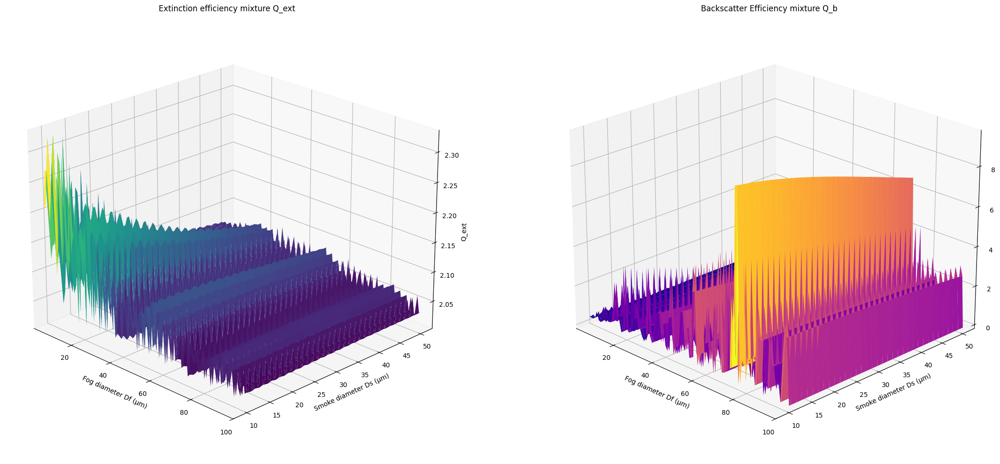

In [ ]:
fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Ds_grid, Df_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
ax1.set_ylim(100.0,0.1)
#ax1.set_xlim(50.0, 10.0)
ax1.set_zlabel('Q_ext')
ax1.set_ylabel('Fog diameter Df (µm)')
ax1.set_xlabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=22.5, azim=225)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Ds_grid, Df_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
ax2.set_ylim(100.0,0.1)
#ax2.set_xlim(50.0, 10.0)
ax2.set_zlabel('Q_b')
ax2.set_ylabel('Fog diameter Df (µm)')
ax2.set_xlabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=22.5, azim=225)

plt.tight_layout()
plt.show()

In [ ]:
for i in range(Df_grid.shape[0]):        # over smoke
    for j in range(Df_grid.shape[1]):    # over fog

        # convert to meters
        Df_m = Df_grid[i, j] * 1e-6      # fog diameter
        Ds_m = Ds_grid[i, j] * 1e-6      # smoke diameter
        print(f"\n==i={i}, j = {j} Df_m={Df_m:.3e} and Ds_m={Ds_m:.3e} m===")

        # per-particle backscatter efficiencies
        Qb_f = qb_for_sphere(m_fog,   Df_m)
        Qb_s = qb_for_sphere(m_smoke, Ds_m)
        Qext_f = qext_for_sphere(m_fog,   Df_m)
        Qext_s = qext_for_sphere(m_smoke, Ds_m)

         # geometric cross-sections
        area_f_d = np.pi * (Df_m / 2.0)**2
        area_s_d = np.pi * (Ds_m / 2.0)**2
        total_area_d = N_f* area_f_d + N_s * area_s_d

        # mixture backscatter per unit volume (relative)
        Q_b[i, j] = N_f * Qb_f * area_f_d + N_s * Qb_s * area_s_d
        Q_b[i,j]/=total_area_d
        Q_ext[i, j] = N_f * Qext_f* area_f_d + N_s * Qext_s* area_s_d
        Q_ext[i,j]/=total_area_d

Streaming output truncated to the last 5000 lines.

==i=76, j = 25 Df_m=2.508e-05 and Ds_m=1.960e-05 m===

==i=76, j = 26 Df_m=2.607e-05 and Ds_m=1.960e-05 m===

==i=76, j = 27 Df_m=2.707e-05 and Ds_m=1.960e-05 m===

==i=76, j = 28 Df_m=2.807e-05 and Ds_m=1.960e-05 m===

==i=76, j = 29 Df_m=2.907e-05 and Ds_m=1.960e-05 m===

==i=76, j = 30 Df_m=3.007e-05 and Ds_m=1.960e-05 m===

==i=76, j = 31 Df_m=3.107e-05 and Ds_m=1.960e-05 m===

==i=76, j = 32 Df_m=3.207e-05 and Ds_m=1.960e-05 m===

==i=76, j = 33 Df_m=3.307e-05 and Ds_m=1.960e-05 m===

==i=76, j = 34 Df_m=3.407e-05 and Ds_m=1.960e-05 m===

==i=76, j = 35 Df_m=3.507e-05 and Ds_m=1.960e-05 m===

==i=76, j = 36 Df_m=3.606e-05 and Ds_m=1.960e-05 m===

==i=76, j = 37 Df_m=3.706e-05 and Ds_m=1.960e-05 m===

==i=76, j = 38 Df_m=3.806e-05 and Ds_m=1.960e-05 m===

==i=76, j = 39 Df_m=3.906e-05 and Ds_m=1.960e-05 m===

==i=76, j = 40 Df_m=4.006e-05 and Ds_m=1.960e-05 m===

==i=76, j = 41 Df_m=4.106e-05 and Ds_m=1.960e-05 m===

==i=76, j = 4

In [ ]:
init=2

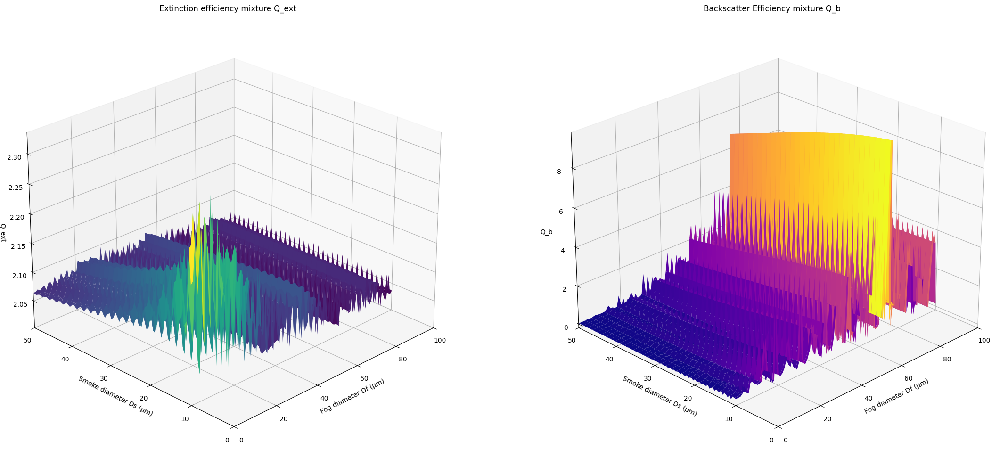

In [ ]:

fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylim(50,0)
ax1.set_xlim(100,0)
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=45)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylim(50,0)
ax2.set_xlim(100,0)
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()

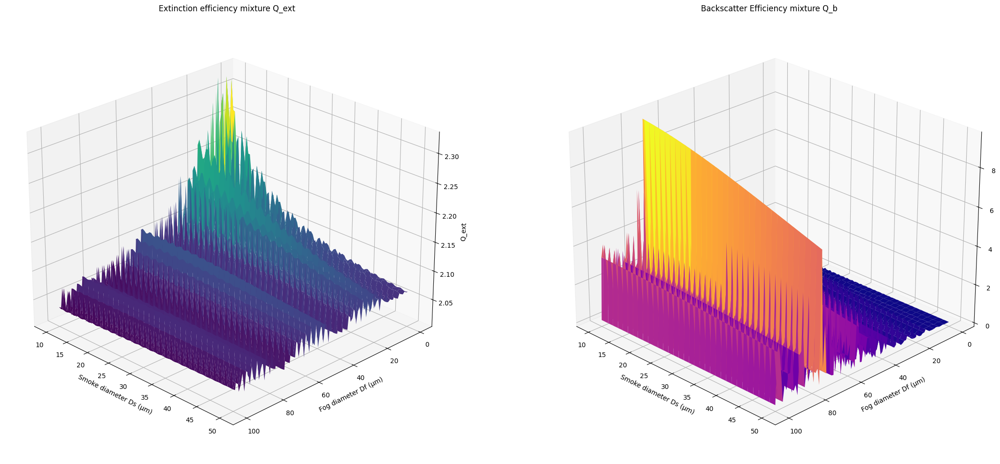

In [ ]:

fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=45)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()

In [ ]:
init=0

In [ ]:
for i in range(Df_grid.shape[0]):        # over smoke
    for j in range(Df_grid.shape[1]):    # over fog
      print("Q_b[",i,j,"]=",Q_b[i,j], "and Q_ext[",i,j,"]=",Q_ext[i,j], "\n")

Streaming output truncated to the last 5000 lines.
Q_b[ 76 25 ]= 1.5057730122593442 and Q_ext[ 76 25 ]= 2.060878407137709 

Q_b[ 76 26 ]= 0.4959993930070817 and Q_ext[ 76 26 ]= 2.131452983163421 

Q_b[ 76 27 ]= 0.4958390166443394 and Q_ext[ 76 27 ]= 2.1527510752776005 

Q_b[ 76 28 ]= 0.23725606521759143 and Q_ext[ 76 28 ]= 2.049518738519213 

Q_b[ 76 29 ]= 0.10208838285915449 and Q_ext[ 76 29 ]= 2.126596298867892 

Q_b[ 76 30 ]= 0.3840755369589927 and Q_ext[ 76 30 ]= 2.1055749264864487 

Q_b[ 76 31 ]= 3.1027304132651103 and Q_ext[ 76 31 ]= 2.049944820818803 

Q_b[ 76 32 ]= 0.44385333423359147 and Q_ext[ 76 32 ]= 2.1639126668273434 

Q_b[ 76 33 ]= 0.18885005749860678 and Q_ext[ 76 33 ]= 2.0851860798772157 

Q_b[ 76 34 ]= 0.3432465607217064 and Q_ext[ 76 34 ]= 2.0708853962207803 

Q_b[ 76 35 ]= 0.6347566405540918 and Q_ext[ 76 35 ]= 2.1312979002622088 

Q_b[ 76 36 ]= 1.5305761886657394 and Q_ext[ 76 36 ]= 2.0448357454035007 

Q_b[ 76 37 ]= 1.7083007788483346 and Q_ext[ 76 37 ]= 2.0871935

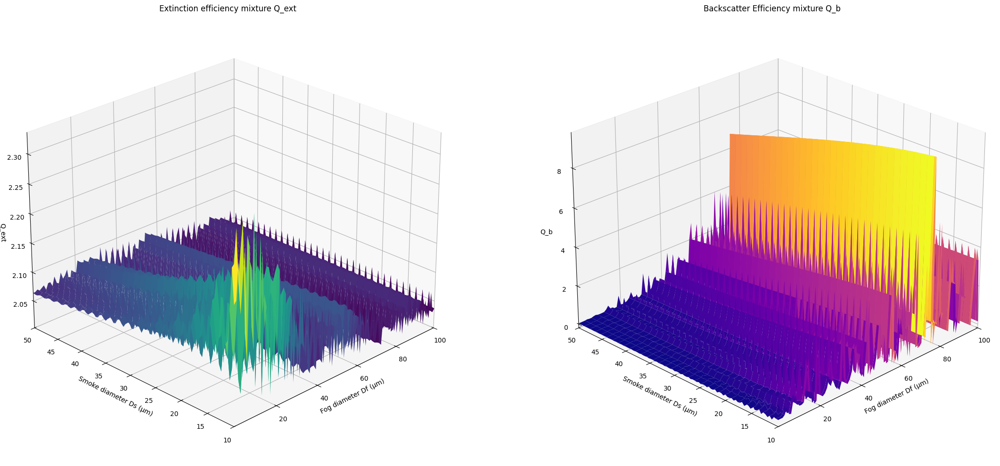

In [ ]:
fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
ax1.set_xlim(100.0,0.1)
ax1.set_ylim(50.0, 10.0)
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=45)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
ax2.set_xlim(100.0,0.1)
ax2.set_ylim(50.0, 10.0)
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()

In [ ]:
fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
ax1.set_xlim(100.0,0.1)
ax1.set_ylim(10.0, 50.0)
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.set_xticks([0, 25, 50, 75, 100])
ax1.set_xticklabels(['0', '25', '50', '75', '100'])

ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=22.5, azim=0)

/tmp/ipython-input-423353519.py:28: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


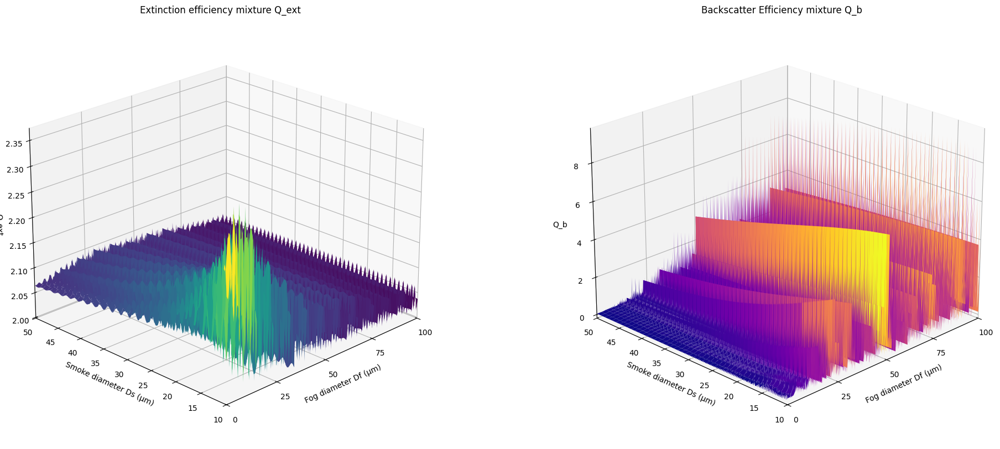

In [ ]:
fig = plt.figure(figsize=(24, 10))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
ax1.set_xlim(0.1,100.0)
ax1.set_ylim(10.0, 50.0)
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.set_xticks([0, 25, 50, 75, 100])
ax1.set_xticklabels(['0', '25', '50', '75', '100'])
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=22.5, azim=-135)
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
ax2.set_xlim(0.1,100.0)
ax2.set_ylim(10.0, 50.0)
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')
ax2.set_xticks([0, 25, 50, 75, 100])
ax2.set_xticklabels(['0', '25', '50', '75', '100'])
ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=22.5, azim=-135)
plt.tight_layout()
plt.show()

In [ ]:
aaaaa

In [ ]:
a

In [ ]:
a

In [ ]:

fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Ds_grid, Df_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction mixture Σ_ext3')
ax1.set_zlabel('Σ_ext3')
ax1.set_ylabel('Fog diameter Df (µm)')
ax1.set_xlim(50,0)
ax1.set_ylim(100,0)
ax1.set_xlabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=45)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Ds_grid, Df_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter mixture Σ_b3')
ax2.set_zlabel('Σ_b3')
ax2.set_ylabel('Fog diameter Df (µm)')
ax2.set_xlim(50,0)
ax2.set_ylim(100,0)
ax2.set_xlabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()

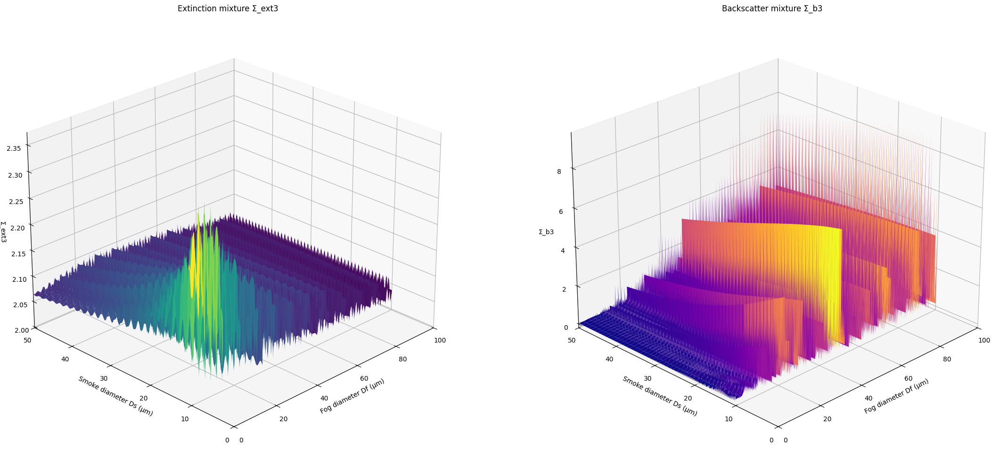

In [ ]:

fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction mixture Σ_ext3')
ax1.set_zlabel('Σ_ext3')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylim(50,0)
ax1.set_xlim(100,0)
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=45)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter mixture Σ_b3')
ax2.set_zlabel('Σ_b3')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylim(50,0)
ax2.set_xlim(100,0)
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()

In [ ]:
bb

In [ ]:
fig = plt.figure(figsize=(20, 16))
ax = fig.add_subplot(111, projection='3d')

# Extinction surface
surf1 = ax.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', alpha=0.7, edgecolor='none',label='Extinction_ext' ) # label used later

# Backscatter surface
surf2 = ax.plot_surface(Df_grid, Ds_grid, Q_b,cmap='plasma', alpha=0.7, edgecolor='none')

ax.set_xlabel('Fog diameter Df (µm)')
ax.set_ylabel('Smoke diameter Ds (µm)')
ax.set_zlabel('Coefficient value')
ax.set_title('Extinction and backscatter mixtures')

# Fake handles for legend
from matplotlib.patches import Patch
handles = [Patch(facecolor='viridis', label='Extinction_ext'), Patch(facecolor='plasma', label='Backscatter_b')]
ax.legend(handles=handles, loc='upper left')

plt.tight_layout()
plt.show()


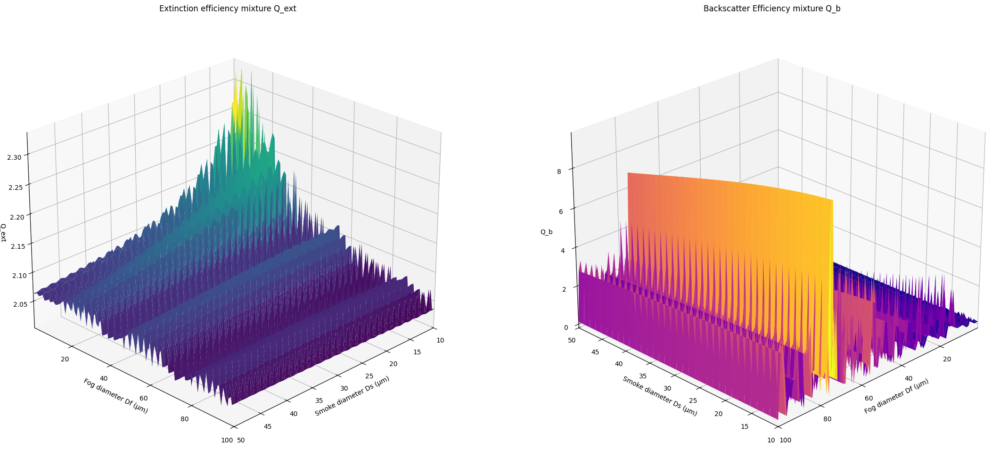

In [ ]:
fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=135)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=-135)

plt.tight_layout()
plt.show()

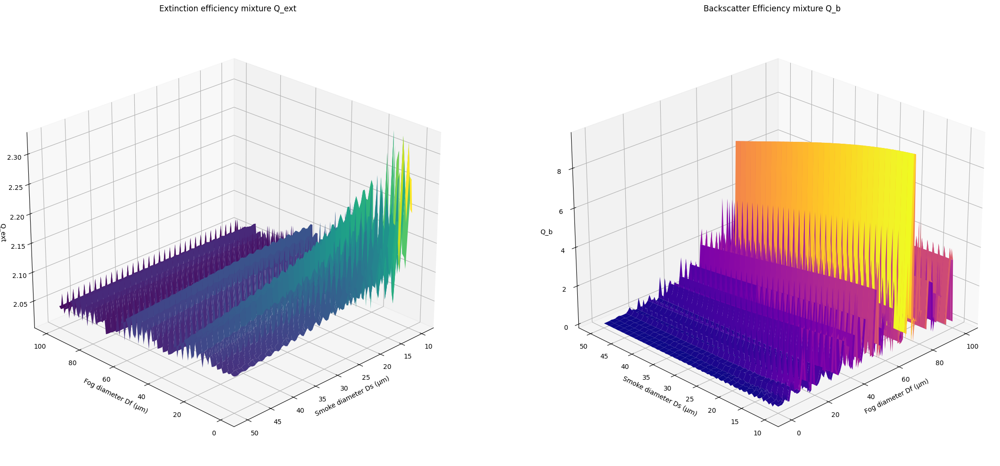

In [ ]:
fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
#ax1.set_xlim(100.0,0.1)
#ax1.set_ylim(10.0, 50.0)
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=135)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
#ax2.set_xlim(100.0,0.1)
#ax2.set_ylim(10.0, 50.0)
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=-135)

plt.tight_layout()
plt.show()

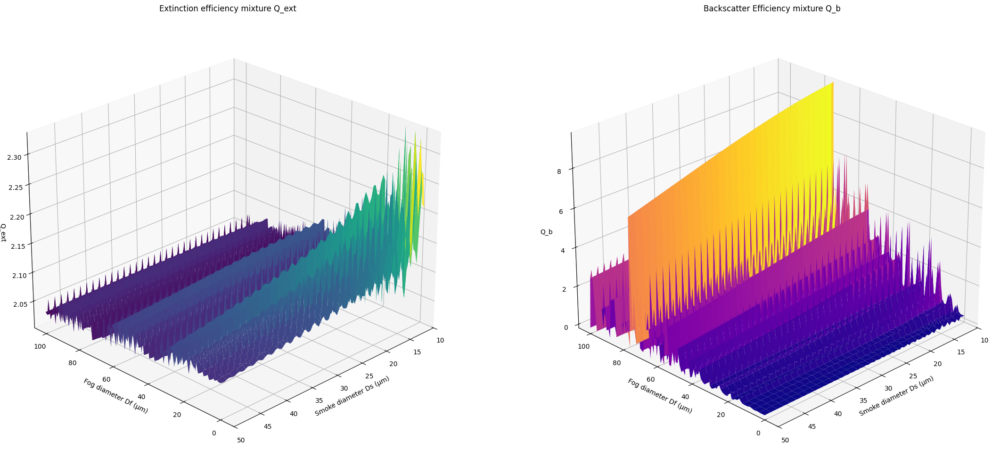

In [ ]:
fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
#ax1.set_xlim(100.0,0.1)
ax1.set_ylim(10.0, 50.0)
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=135)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
#ax2.set_xlim(100.0,0.1)
#ax2.set_ylim(10.0, 50.0)
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=135)

plt.tight_layout()
plt.show()

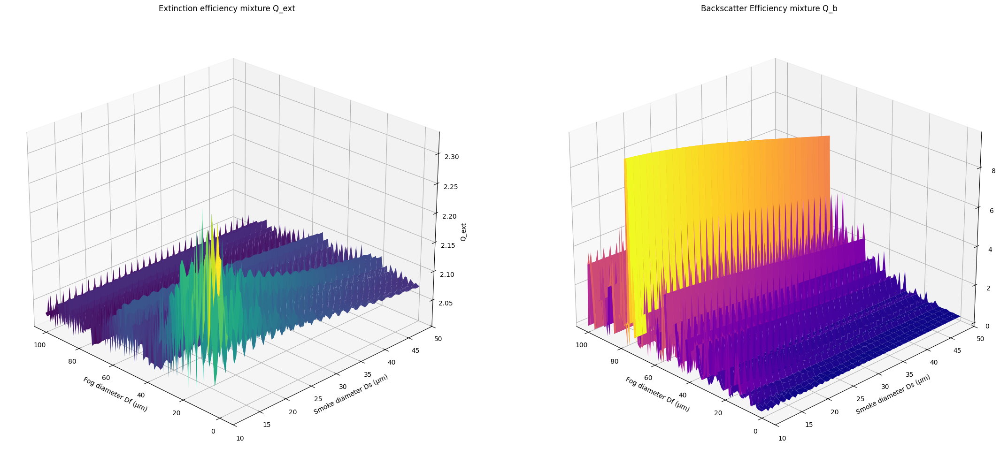

In [ ]:
fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
#ax1.set_xlim(100.0,0.1)
ax1.set_ylim(50.0, 10.0)
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=135)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
#ax2.set_xlim(100.0,0.1)
ax2.set_ylim(50.0, 10.0)
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=135)

plt.tight_layout()
plt.show()

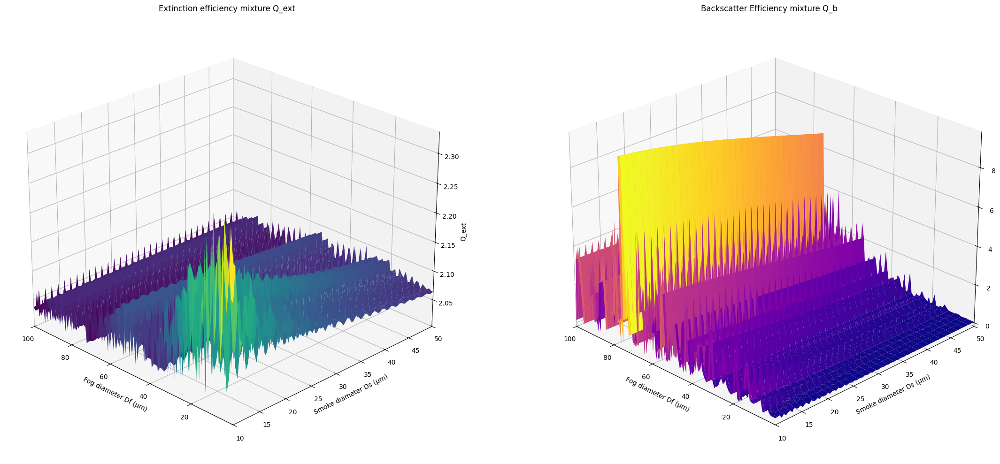

In [ ]:
fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
ax1.set_xlim(100.0,0.1)
ax1.set_ylim(10.0, 50.0)
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=-45)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
ax2.set_xlim(100.0,0.1)
ax2.set_ylim(10.0, 50.0)
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=-45)

plt.tight_layout()
plt.show()

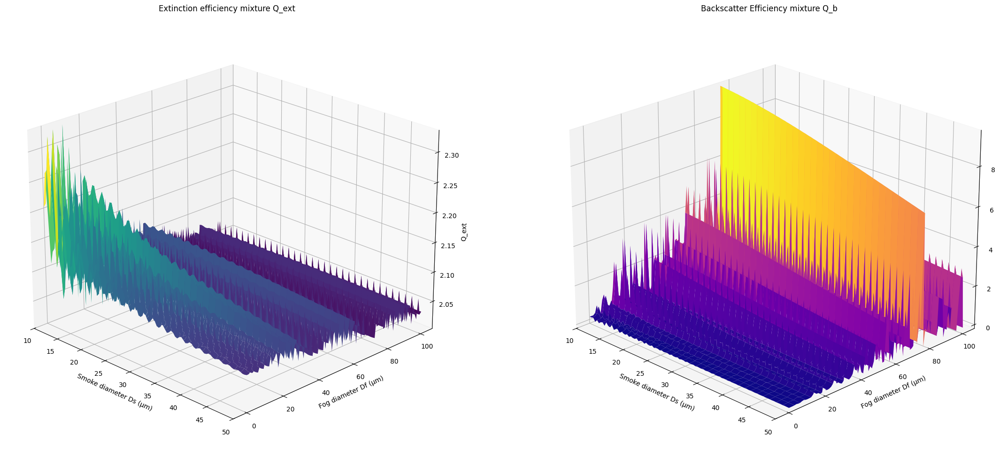

In [ ]:
fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
#ax1.set_xlim(100.0,0.1)
ax1.set_ylim(50.0, 10.0)
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=22.5, azim=225)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
#ax2.set_xlim(100.0,0.1)
ax2.set_ylim(50.0, 10.0)
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=22.5, azim=225)

plt.tight_layout()
plt.show()

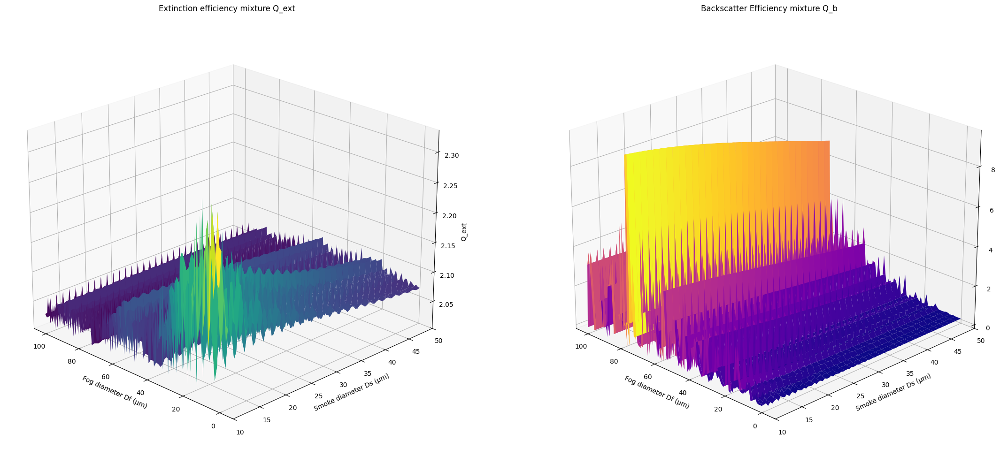

In [ ]:
fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
#ax1.set_xlim(100.0,0.1)
ax1.set_ylim(50.0, 10.0)
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=22.5, azim=135)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
#ax2.set_xlim(100.0,0.1)
ax2.set_ylim(50.0, 10.0)
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=22.5, azim=135)

plt.tight_layout()
plt.show()

In [ ]:
# --- Physical parameters ---
wavelength = 905e-9          # LiDAR wavelength, meters
m_fog   = 1.33 + 0j          # refractive index fog droplets (water approx)
m_smoke = 1.50 + 0.01j       # example smoke index; adjust as needed

N_f = 1.0                    # relative number density, fog
N_s = 1.0                    # relative number density, smoke

# --- Size grids (in micrometers for plotting) ---
Df_um = np.linspace(0.1, 100, 101)
Ds_um = np.linspace(10.0, 50.0, 101)

In [ ]:
Ds_grid, Df_grid = np.meshgrid(Ds_um, Df_um)

In [ ]:
fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
ax1.set_xlim(100.0,0.1)
ax1.set_ylim(10.0, 50.0)
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=-45)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
ax2.set_xlim(100.0,0.1)
ax2.set_ylim(10.0, 50.0)
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=-45)

plt.tight_layout()
plt.show()

In [ ]:
# --- Physical parameters ---
wavelength = 905e-9          # LiDAR wavelength, meters
m_fog   = 1.33 + 0j          # refractive index fog droplets (water approx)
m_smoke = 1.50 + 0.01j       # example smoke index; adjust as needed

N_f = 1.0                    # relative number density, fog
N_s = 1.0                    # relative number density, smoke

# --- Size grids (in micrometers for plotting) ---
Df_um = np.linspace(0.1, 100, 101)
Ds_um = np.linspace(10.0, 50.0, 101)

In [ ]:
Df_grid, Ds_grid = np.meshgrid(Df_um, Ds_um)

In [ ]:
Q_b = np.zeros_like(Df_grid, dtype=float) # z-axis: mixture backscatter
Q_ext = np.zeros_like(Ds_grid, dtype=float) # z-axis: mixture extinction

In [ ]:
# --- Helper to compute Qb for one species ---
def qb_for_sphere(m, D_m):
    x = np.pi * D_m / wavelength          # size parameter
    qext, qsca, qback, g = miepython.efficiencies_mx(m, x)
    return qback

def qext_for_sphere(m, D_m):
    x = np.pi * D_m / wavelength          # size parameter
    qext, qsca, qback, g = miepython.efficiencies_mx(m, x)
    return qext

In [ ]:
for i in range(Df_grid.shape[0]):        # over smoke
    for j in range(Df_grid.shape[1]):    # over fog

        # convert to meters
        Df_m = Df_grid[i, j] * 1e-6      # fog diameter
        Ds_m = Ds_grid[i, j] * 1e-6      # smoke diameter
        print(f"\n==i={i}, j = {j} Df_m={Df_m:.3e} and Ds_m={Ds_m:.3e} m===")

        # per-particle backscatter efficiencies
        Qb_f = qb_for_sphere(m_fog,   Df_m)
        Qb_s = qb_for_sphere(m_smoke, Ds_m)
        Qext_f = qext_for_sphere(m_fog,   Df_m)
        Qext_s = qext_for_sphere(m_smoke, Ds_m)

         # geometric cross-sections
        area_f_d = np.pi * (Df_m / 2.0)**2
        area_s_d = np.pi * (Ds_m / 2.0)**2
        total_area_d = N_f* area_f_d + N_s * area_s_d

        # mixture backscatter per unit volume (relative)
        Q_b[i, j] = N_f * Qb_f * area_f_d + N_s * Qb_s * area_s_d
        Q_b[i,j]/=total_area_d
        Q_ext[i, j] = N_f * Qext_f* area_f_d + N_s * Qext_s* area_s_d
        Q_ext[i,j]/=total_area_d

Streaming output truncated to the last 5000 lines.

==i=76, j = 25 Df_m=2.508e-05 and Ds_m=4.040e-05 m===

==i=76, j = 26 Df_m=2.607e-05 and Ds_m=4.040e-05 m===

==i=76, j = 27 Df_m=2.707e-05 and Ds_m=4.040e-05 m===

==i=76, j = 28 Df_m=2.807e-05 and Ds_m=4.040e-05 m===

==i=76, j = 29 Df_m=2.907e-05 and Ds_m=4.040e-05 m===

==i=76, j = 30 Df_m=3.007e-05 and Ds_m=4.040e-05 m===

==i=76, j = 31 Df_m=3.107e-05 and Ds_m=4.040e-05 m===

==i=76, j = 32 Df_m=3.207e-05 and Ds_m=4.040e-05 m===

==i=76, j = 33 Df_m=3.307e-05 and Ds_m=4.040e-05 m===

==i=76, j = 34 Df_m=3.407e-05 and Ds_m=4.040e-05 m===

==i=76, j = 35 Df_m=3.507e-05 and Ds_m=4.040e-05 m===

==i=76, j = 36 Df_m=3.606e-05 and Ds_m=4.040e-05 m===

==i=76, j = 37 Df_m=3.706e-05 and Ds_m=4.040e-05 m===

==i=76, j = 38 Df_m=3.806e-05 and Ds_m=4.040e-05 m===

==i=76, j = 39 Df_m=3.906e-05 and Ds_m=4.040e-05 m===

==i=76, j = 40 Df_m=4.006e-05 and Ds_m=4.040e-05 m===

==i=76, j = 41 Df_m=4.106e-05 and Ds_m=4.040e-05 m===

==i=76, j = 4

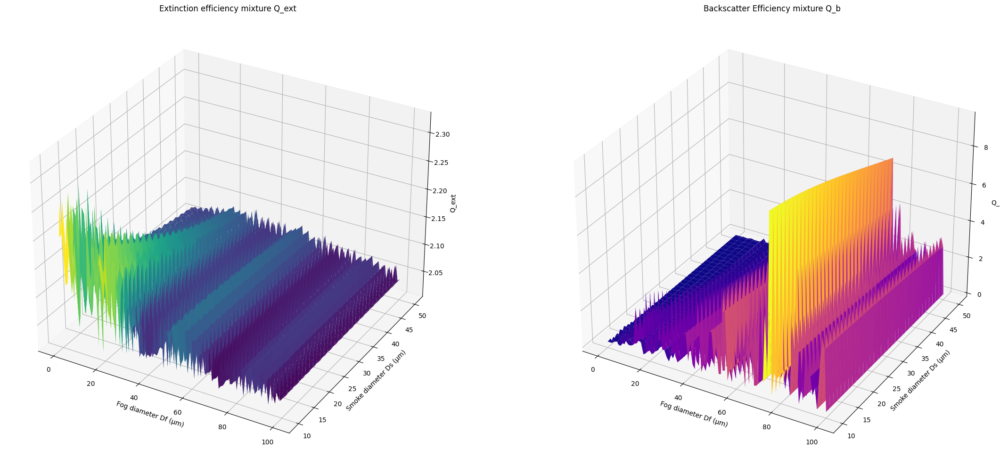

In [ ]:

fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')

plt.tight_layout()
plt.show()

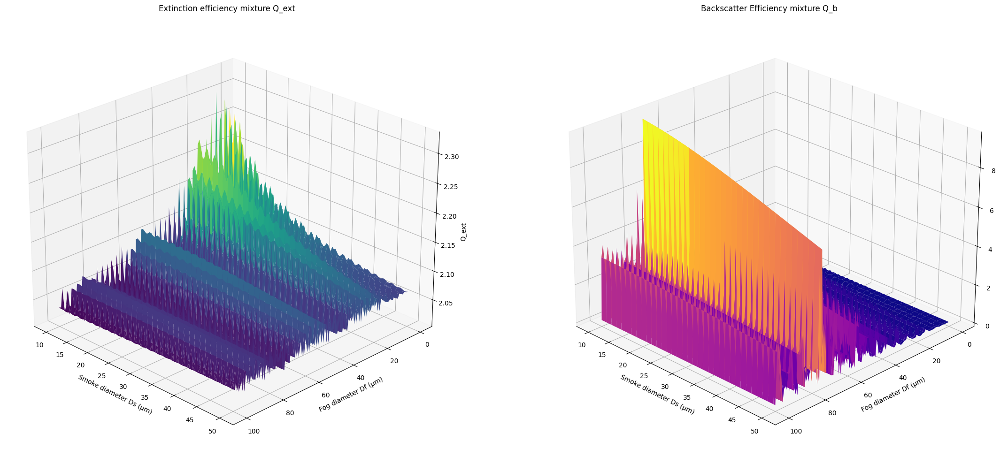

In [ ]:

fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=45)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()

In [ ]:

fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid, Ds_grid, Q_ext, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction efficiency mixture Q_ext')
ax1.set_zlabel('Q_ext')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=45)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid, Ds_grid, Q_b, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter Efficiency mixture Q_b')
ax2.set_zlabel('Q_b')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import miepython  # pip install miepython

# 1) Parameters
wavelength = 905e-9          # 905 nm, in meters
m = 1.50 + 0.01j               # example refractive index of water at 905 nm (set appropriately)

# 2) Diameter grid (in meters)
D_um = np.linspace(0.5,50.5, 501)   # 0.1–50 micrometers, adjust to match paper
D = D_um * 1e-6
X= D * np.pi/wavelength
X

array([  1.73568655,   2.08282386,   2.42996117,   2.77709848,
         3.12423579,   3.4713731 ,   3.81851041,   4.16564772,
         4.51278503,   4.85992234,   5.20705965,   5.55419696,
         5.90133427,   6.24847158,   6.59560889,   6.9427462 ,
         7.28988351,   7.63702082,   7.98415813,   8.33129543,
         8.67843274,   9.02557005,   9.37270736,   9.71984467,
        10.06698198,  10.41411929,  10.7612566 ,  11.10839391,
        11.45553122,  11.80266853,  12.14980584,  12.49694315,
        12.84408046,  13.19121777,  13.53835508,  13.88549239,
        14.2326297 ,  14.57976701,  14.92690432,  15.27404163,
        15.62117894,  15.96831625,  16.31545356,  16.66259087,
        17.00972818,  17.35686549,  17.7040028 ,  18.05114011,
        18.39827742,  18.74541473,  19.09255204,  19.43968935,
        19.78682666,  20.13396397,  20.48110128,  20.82823859,
        21.1753759 ,  21.52251321,  21.86965052,  22.21678783,
        22.56392514,  22.91106245,  23.25819976,  23.60

In [ ]:

# 3) Compute efficiencies
Qext = np.zeros_like(D)
Qb   = np.zeros_like(D)

for i, d in enumerate(D):
    print(i,"\n")
    x = np.pi * d / wavelength
    qext, qsca, qback, g = miepython.efficiencies_mx(m, x)
    Qext[i] = qext
    Qb[i]   = qback

0 

1 

2 

3 

4 

5 

6 

7 

8 

9 

10 

11 

12 

13 

14 

15 

16 

17 

18 

19 

20 

21 

22 

23 

24 

25 

26 

27 

28 

29 

30 

31 

32 

33 

34 

35 

36 

37 

38 

39 

40 

41 

42 

43 

44 

45 

46 

47 

48 

49 

50 

51 

52 

53 

54 

55 

56 

57 

58 

59 

60 

61 

62 

63 

64 

65 

66 

67 

68 

69 

70 

71 

72 

73 

74 

75 

76 

77 

78 

79 

80 

81 

82 

83 

84 

85 

86 

87 

88 

89 

90 

91 

92 

93 

94 

95 

96 

97 

98 

99 

100 

101 

102 

103 

104 

105 

106 

107 

108 

109 

110 

111 

112 

113 

114 

115 

116 

117 

118 

119 

120 

121 

122 

123 

124 

125 

126 

127 

128 

129 

130 

131 

132 

133 

134 

135 

136 

137 

138 

139 

140 

141 

142 

143 

144 

145 

146 

147 

148 

149 

150 

151 

152 

153 

154 

155 

156 

157 

158 

159 

160 

161 

162 

163 

164 

165 

166 

167 

168 

169 

170 

171 

172 

173 

174 

175 

176 

177 

178 

179 

180 

181 

182 

183 

184 



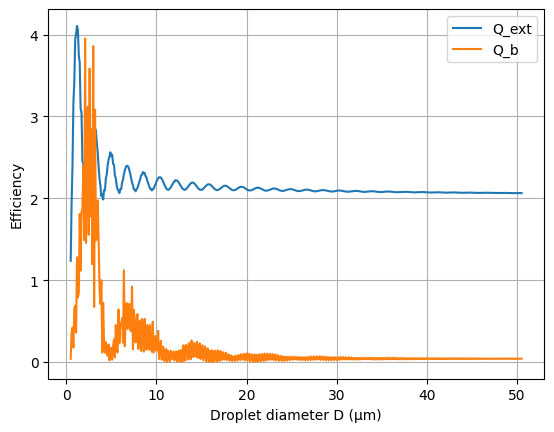

In [ ]:

# 4) Plot
plt.figure()
plt.plot(D_um, Qext, label='Q_ext')
plt.plot(D_um, Qb,   label='Q_b')
plt.xlabel('Droplet diameter D (µm)')
plt.ylabel('Efficiency')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import miepython  # pip install miepython

# 1) Parameters
wavelength = 905e-9          # 905 nm, in meters
m = 1.33 + 0j                # example refractive index of water at 905 nm (set appropriately)

# 2) Diameter grid (in meters)
D_um = np.linspace(0.5,100.5, 101)   # 0.1–50 micrometers, adjust to match paper
D = D_um * 1e-6
X= D * np.pi/wavelength
X

array([  1.73568655,   5.20705965,   8.67843274,  12.14980584,
        15.62117894,  19.09255204,  22.56392514,  26.03529823,
        29.50667133,  32.97804443,  36.44941753,  39.92079063,
        43.39216372,  46.86353682,  50.33490992,  53.80628302,
        57.27765612,  60.74902921,  64.22040231,  67.69177541,
        71.16314851,  74.6345216 ,  78.1058947 ,  81.5772678 ,
        85.0486409 ,  88.520014  ,  91.99138709,  95.46276019,
        98.93413329, 102.40550639, 105.87687949, 109.34825258,
       112.81962568, 116.29099878, 119.76237188, 123.23374498,
       126.70511807, 130.17649117, 133.64786427, 137.11923737,
       140.59061046, 144.06198356, 147.53335666, 151.00472976,
       154.47610286, 157.94747595, 161.41884905, 164.89022215,
       168.36159525, 171.83296835, 175.30434144, 178.77571454,
       182.24708764, 185.71846074, 189.18983383, 192.66120693,
       196.13258003, 199.60395313, 203.07532623, 206.54669932,
       210.01807242, 213.48944552, 216.96081862, 220.43

In [ ]:
miepython.efficiencies( (1.33+0j) , 50.33490991939448 , 9.05e-07 )

(np.float64(2.0000057813090097),
 np.float64(2.0000057813090097),
 np.float64(144.42892117376144),
 np.float64(0.8853220832816855))

In [ ]:
for i, d in enumerate(X):
  print(i, ") " ,"miepython.efficiencies(", m, ",", d, ",", wavelength, ")\n")

0 )  miepython.efficiencies( (1.33+0j) , 1.735686548944637 , 9.05e-07 )

1 )  miepython.efficiencies( (1.33+0j) , 5.207059646833911 , 9.05e-07 )

2 )  miepython.efficiencies( (1.33+0j) , 8.678432744723185 , 9.05e-07 )

3 )  miepython.efficiencies( (1.33+0j) , 12.14980584261246 , 9.05e-07 )

4 )  miepython.efficiencies( (1.33+0j) , 15.621178940501734 , 9.05e-07 )

5 )  miepython.efficiencies( (1.33+0j) , 19.092552038391005 , 9.05e-07 )

6 )  miepython.efficiencies( (1.33+0j) , 22.563925136280282 , 9.05e-07 )

7 )  miepython.efficiencies( (1.33+0j) , 26.035298234169552 , 9.05e-07 )

8 )  miepython.efficiencies( (1.33+0j) , 29.50667133205883 , 9.05e-07 )

9 )  miepython.efficiencies( (1.33+0j) , 32.9780444299481 , 9.05e-07 )

10 )  miepython.efficiencies( (1.33+0j) , 36.449417527837376 , 9.05e-07 )

11 )  miepython.efficiencies( (1.33+0j) , 39.92079062572665 , 9.05e-07 )

12 )  miepython.efficiencies( (1.33+0j) , 43.39216372361592 , 9.05e-07 )

13 )  miepython.efficiencies( (1.33+0j) , 46

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import miepython

In [ ]:
# --- Physical parameters ---
wavelength = 905e-9          # LiDAR wavelength, meters
m_fog   = 1.33 + 0j          # refractive index fog droplets (water approx)
m_smoke = 1.50 + 0.01j       # example smoke index; adjust as needed

N_f = 1.0                    # relative number density, fog
N_s = 1.0                    # relative number density, smoke

# --- Size grids (in micrometers for plotting) ---
Df_um = np.linspace(0.1, 100.1, 51)     # fog diameters: 1–50 µm
Ds_um = np.linspace(50.1, 0.1,51)     # smoke diameters: 0.1–10 µm
Df_umx= np.linspace(0.1, 100.1, 101)     # fog diameters: 1–50 µm
Ds_umx= np.linspace(50.1, 0.1, 101)     # smoke diameters: 0.1–10 µm

In [ ]:
Df_grid3, Ds_grid3 = np.meshgrid(Df_um, Ds_um)   # shape (50, 50)
Df_grid3x, Ds_grid3x = np.meshgrid(Df_umx, Ds_umx)   # shape (50, 50)
print(Df_grid3)
print(Ds_grid3)

[[1.000e-01 2.100e+00 4.100e+00 ... 9.610e+01 9.810e+01 1.001e+02]
 [1.000e-01 2.100e+00 4.100e+00 ... 9.610e+01 9.810e+01 1.001e+02]
 [1.000e-01 2.100e+00 4.100e+00 ... 9.610e+01 9.810e+01 1.001e+02]
 ...
 [1.000e-01 2.100e+00 4.100e+00 ... 9.610e+01 9.810e+01 1.001e+02]
 [1.000e-01 2.100e+00 4.100e+00 ... 9.610e+01 9.810e+01 1.001e+02]
 [1.000e-01 2.100e+00 4.100e+00 ... 9.610e+01 9.810e+01 1.001e+02]]
[[50.1 50.1 50.1 ... 50.1 50.1 50.1]
 [49.1 49.1 49.1 ... 49.1 49.1 49.1]
 [48.1 48.1 48.1 ... 48.1 48.1 48.1]
 ...
 [ 2.1  2.1  2.1 ...  2.1  2.1  2.1]
 [ 1.1  1.1  1.1 ...  1.1  1.1  1.1]
 [ 0.1  0.1  0.1 ...  0.1  0.1  0.1]]


In [ ]:
initial=0

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import miepython

In [ ]:
Df_um = np.linspace(0.1, 100.1,51)     # fog diameters: 1–50 µm
Ds_um = np.linspace(50.1, 0.1, 51)     # smoke diameters: 0.1–10 µm

Df_grid3, Ds_grid3 = np.meshgrid(Df_um, Ds_um)   # shape (50, 50)

In [ ]:
Sigma_b3 = np.zeros_like(Df_grid3, dtype=float) # z-axis: mixture backscatter
Sigma_ext3 = np.zeros_like(Ds_grid3, dtype=float) # z-axis: mixture extinction
Sigma_b3x = np.zeros_like(Df_grid3x, dtype=float) # z-axis: mixture backscatter
Sigma_ext3x = np.zeros_like(Ds_grid3x, dtype=float) # z-axis: mixture extinction


In [ ]:

# --- Helper to compute Qb for one species ---
def qb_for_sphere(m, D_m):
    x = np.pi * D_m / wavelength          # size parameter
    qext, qsca, qback, g = miepython.efficiencies_mx(m, x)
    return qback

def qext_for_sphere(m, D_m):
    x = np.pi * D_m / wavelength          # size parameter
    qext, qsca, qback, g = miepython.efficiencies_mx(m, x)
    return qext

In [ ]:
i=0

In [ ]:
for i in range(Df_grid3x.shape[0]):        # over smoke
    for j in range(Df_grid3x.shape[1]):    # over fog

        # convert to meters
        Df_m3x = Df_grid3x[i, j] * 1e-6      # fog diameter
        Ds_m3x = Ds_grid3x[i, j] * 1e-6      # smoke diameter
        print(f"\n==i={i}, j = {j} Df_m={Df_m3x:.3e} and Ds_m={Ds_m3x:.3e} m===")

        # per-particle backscatter efficiencies
        Qb_f3x = qb_for_sphere(m_fog,   Df_m3x)
        Qb_s3x = qb_for_sphere(m_smoke, Ds_m3x)
        Qext_f3x = qext_for_sphere(m_fog,   Df_m3x)
        Qext_s3x = qext_for_sphere(m_smoke, Ds_m3x)

         # geometric cross-sections
        sigma_f3x = np.pi * (Df_m3x / 2.0)**2
        sigma_s3x = np.pi * (Ds_m3x / 2.0)**2
        sigma_totalx=N_f* sigma_f3x + N_s * sigma_s3x

        # mixture backscatter per unit volume (relative)
        Sigma_b3x[i, j] = N_f * Qb_f3x * sigma_f3x + N_s * Qb_s3x * sigma_s3x
        Sigma_b3x[i,j]/=sigma_totalx
        Sigma_ext3x[i, j] = N_f * Qext_f3x* sigma_f3x + N_s * Qext_s3x* sigma_s3x
        Sigma_ext3x[i,j]/=sigma_totalx
        #Sigma_b3[i, j]x = N_f * Qb_f3x  + N_s * Qb_s3x
        #Sigma_ext3[i, j]x = N_f * Qext_f3x + N_s * Qext_s3x

Streaming output truncated to the last 5000 lines.

==i=76, j = 25 Df_m=2.510e-05 and Ds_m=1.210e-05 m===

==i=76, j = 26 Df_m=2.610e-05 and Ds_m=1.210e-05 m===

==i=76, j = 27 Df_m=2.710e-05 and Ds_m=1.210e-05 m===

==i=76, j = 28 Df_m=2.810e-05 and Ds_m=1.210e-05 m===

==i=76, j = 29 Df_m=2.910e-05 and Ds_m=1.210e-05 m===

==i=76, j = 30 Df_m=3.010e-05 and Ds_m=1.210e-05 m===

==i=76, j = 31 Df_m=3.110e-05 and Ds_m=1.210e-05 m===

==i=76, j = 32 Df_m=3.210e-05 and Ds_m=1.210e-05 m===

==i=76, j = 33 Df_m=3.310e-05 and Ds_m=1.210e-05 m===

==i=76, j = 34 Df_m=3.410e-05 and Ds_m=1.210e-05 m===

==i=76, j = 35 Df_m=3.510e-05 and Ds_m=1.210e-05 m===

==i=76, j = 36 Df_m=3.610e-05 and Ds_m=1.210e-05 m===

==i=76, j = 37 Df_m=3.710e-05 and Ds_m=1.210e-05 m===

==i=76, j = 38 Df_m=3.810e-05 and Ds_m=1.210e-05 m===

==i=76, j = 39 Df_m=3.910e-05 and Ds_m=1.210e-05 m===

==i=76, j = 40 Df_m=4.010e-05 and Ds_m=1.210e-05 m===

==i=76, j = 41 Df_m=4.110e-05 and Ds_m=1.210e-05 m===

==i=76, j = 4

In [ ]:
for i in range(Df_grid3.shape[0]):        # over smoke
    for j in range(Df_grid3.shape[1]):    # over fog

        # convert to meters
        Df_m3 = Df_grid3[i, j] * 1e-6      # fog diameter
        Ds_m3 = Ds_grid3[i, j] * 1e-6      # smoke diameter
        print(f"\n==i={i}, j = {j} Df_m={Df_m3:.3e} and Ds_m={Ds_m3:.3e} m===")

        # per-particle backscatter efficiencies
        Qb_f3 = qb_for_sphere(m_fog,   Df_m3)
        Qb_s3 = qb_for_sphere(m_smoke, Ds_m3)
        Qext_f3 = qext_for_sphere(m_fog,   Df_m3)
        Qext_s3 = qext_for_sphere(m_smoke, Ds_m3)

         # geometric cross-sections
        sigma_f3 = np.pi * (Df_m3 / 2.0)**2
        sigma_s3 = np.pi * (Ds_m3 / 2.0)**2
        sigma_total=N_f* sigma_f3 + N_s * sigma_s3

        # mixture backscatter per unit volume (relative)
        Sigma_b3[i, j] = N_f * Qb_f3 * sigma_f3 + N_s * Qb_s3 * sigma_s3
        Sigma_b3[i,j]/=sigma_total
        Sigma_ext3[i, j] = N_f * Qext_f3 * sigma_f3 + N_s * Qext_s3* sigma_s3
        Sigma_ext3[i,j]/=sigma_total
        #Sigma_b3[i, j] = N_f * Qb_f3  + N_s * Qb_s3
        #Sigma_ext3[i, j] = N_f * Qext_f3 + N_s * Qext_s3

Streaming output truncated to the last 5000 lines.

==i=1, j = 50 Df_m=1.000e-07 and Ds_m=2.100e-06 m===

==i=2, j = 0 Df_m=5.010e-05 and Ds_m=4.100e-06 m===

==i=2, j = 1 Df_m=4.910e-05 and Ds_m=4.100e-06 m===

==i=2, j = 2 Df_m=4.810e-05 and Ds_m=4.100e-06 m===

==i=2, j = 3 Df_m=4.710e-05 and Ds_m=4.100e-06 m===

==i=2, j = 4 Df_m=4.610e-05 and Ds_m=4.100e-06 m===

==i=2, j = 5 Df_m=4.510e-05 and Ds_m=4.100e-06 m===

==i=2, j = 6 Df_m=4.410e-05 and Ds_m=4.100e-06 m===

==i=2, j = 7 Df_m=4.310e-05 and Ds_m=4.100e-06 m===

==i=2, j = 8 Df_m=4.210e-05 and Ds_m=4.100e-06 m===

==i=2, j = 9 Df_m=4.110e-05 and Ds_m=4.100e-06 m===

==i=2, j = 10 Df_m=4.010e-05 and Ds_m=4.100e-06 m===

==i=2, j = 11 Df_m=3.910e-05 and Ds_m=4.100e-06 m===

==i=2, j = 12 Df_m=3.810e-05 and Ds_m=4.100e-06 m===

==i=2, j = 13 Df_m=3.710e-05 and Ds_m=4.100e-06 m===

==i=2, j = 14 Df_m=3.610e-05 and Ds_m=4.100e-06 m===

==i=2, j = 15 Df_m=3.510e-05 and Ds_m=4.100e-06 m===

==i=2, j = 16 Df_m=3.410e-05 and Ds_m=4.

In [ ]:
init=0

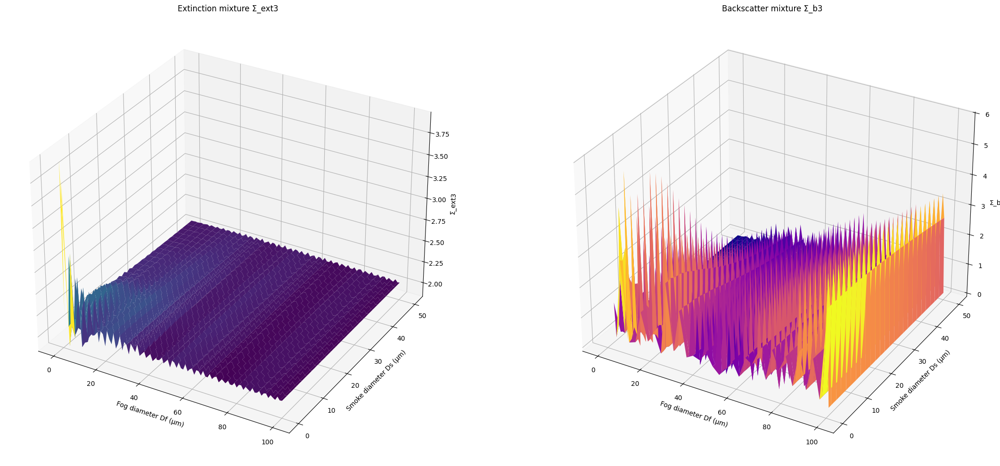

In [ ]:
fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid3, Ds_grid3, Sigma_ext3, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction mixture Σ_ext3')
ax1.set_zlabel('Σ_ext3')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
#ax1.view_init(elev=25, azim=135)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid3, Ds_grid3, Sigma_b3, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter mixture Σ_b3')
ax2.set_zlabel('Σ_b3')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
#ax2.view_init(elev=25, azim=135)

plt.tight_layout()
plt.show()

ValueError: Invalid RGBA argument: 'viridis'

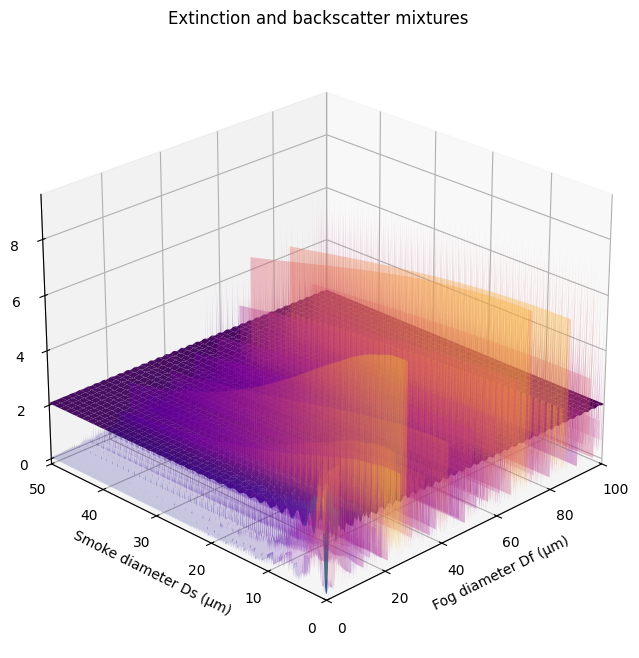

In [ ]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Extinction surface
surf1 = ax.plot_surface(Df_grid3, Ds_grid3, Sigma_ext3, cmap='viridis', alpha=1.0 , edgecolor='none',label='Extinction Σ_ext3' ) # label used later

# Backscatter surface
surf2 = ax.plot_surface(Df_grid3, Ds_grid3, Sigma_b3,cmap='plasma', alpha=0.2, edgecolor='none')

ax.set_xlabel('Fog diameter Df (µm)')
ax.set_ylabel('Smoke diameter Ds (µm)')
ax.set_zlabel('Coefficient value')
ax.set_title('Extinction and backscatter mixtures')
ax.set_ylim(50,0)
ax.set_xlim(100,0)
ax.view_init(elev=25, azim=45)
# Fake handles for legend
from matplotlib.patches import Patch
handles = [Patch(facecolor='viridis', label='Extinction Σ_ext3'), Patch(facecolor='plasma', label='Backscatter Σ_b3')]
ax.legend(handles=handles, loc='upper left')

plt.tight_layout()
plt.show()


/tmp/ipython-input-179308945.py:32: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


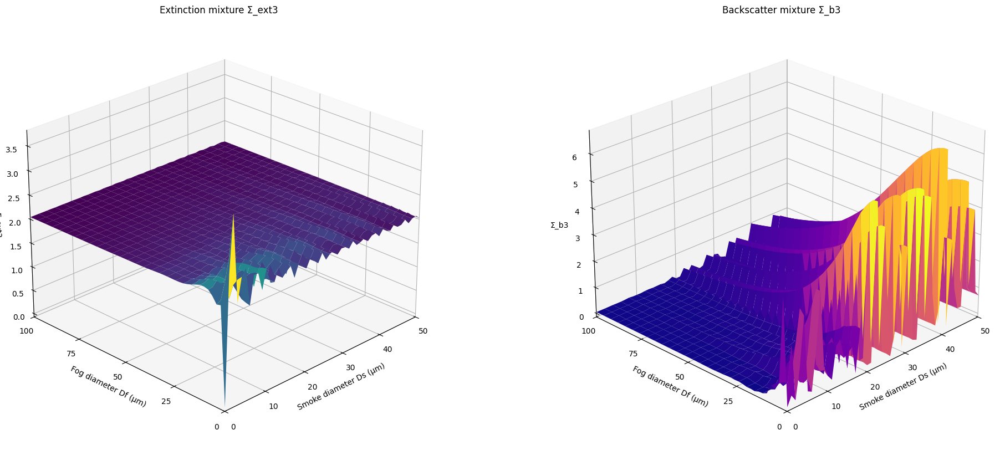

In [ ]:

fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid3, Ds_grid3, Sigma_ext3, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction mixture Σ_ext3')
ax1.set_zlabel('Σ_ext3')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylim(50,0)
ax1.set_xlim(100,0)
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=45)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid3, Ds_grid3, Sigma_b3, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter mixture Σ_b3')
ax2.set_zlabel('Σ_b3')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylim(50,0)
ax2.set_xlim(100,0)
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()

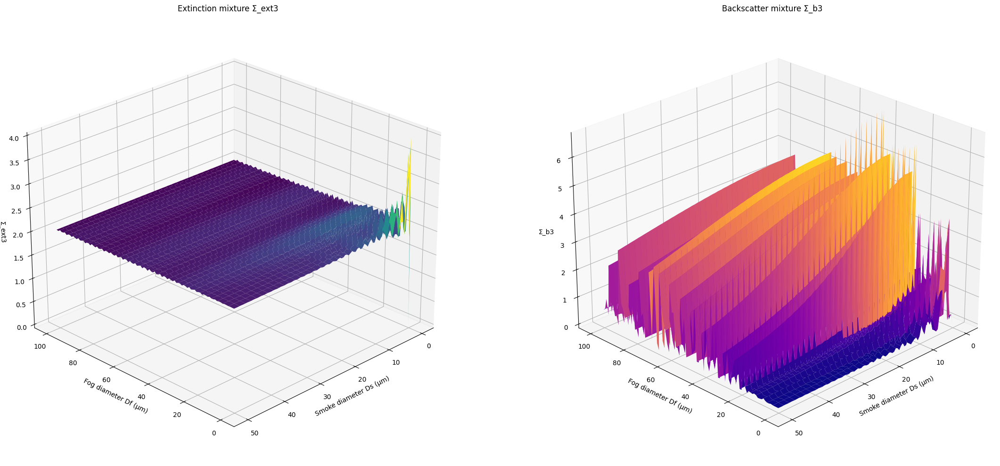

In [ ]:




fig = plt.figure(figsize=(24, 10))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid3x, Ds_grid3x, Sigma_ext3x, cmap='viridis', edgecolor='none')
ax1.set_title('Extinction mixture Σ_ext3')
ax1.set_zlabel('Σ_ext3')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.zaxis.set_ticks_position('upper')
ax1.zaxis.set_label_position('upper')
ax1.view_init(elev=25, azim=135)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid3x, Ds_grid3x, Sigma_b3x, cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter mixture Σ_b3')
ax2.set_zlabel('Σ_b3')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')

ax2.zaxis.set_ticks_position('upper')
ax2.zaxis.set_label_position('upper')
ax2.view_init(elev=25, azim=135)

plt.tight_layout()
plt.show()

ValueError: Invalid RGBA argument: 'viridis'

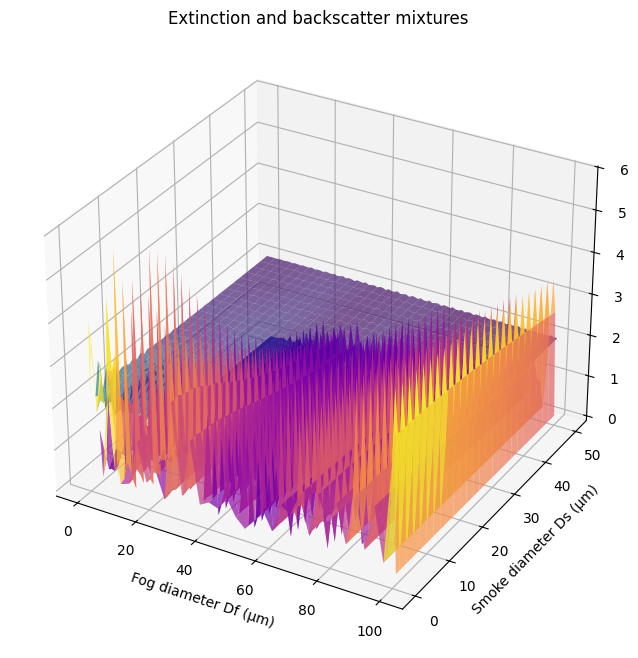

In [ ]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Extinction surface
surf1 = ax.plot_surface(Df_grid3, Ds_grid3, Sigma_ext3, cmap='viridis', alpha=0.7, edgecolor='none',label='Extinction Σ_ext3' ) # label used later

# Backscatter surface
surf2 = ax.plot_surface(Df_grid3, Ds_grid3, Sigma_b3,cmap='plasma', alpha=0.7, edgecolor='none')

ax.set_xlabel('Fog diameter Df (µm)')
ax.set_ylabel('Smoke diameter Ds (µm)')
ax.set_zlabel('Coefficient value')
ax.set_title('Extinction and backscatter mixtures')

# Fake handles for legend
from matplotlib.patches import Patch
handles = [Patch(facecolor='viridis', label='Extinction Σ_ext3'), Patch(facecolor='plasma', label='Backscatter Σ_b3')]
ax.legend(handles=handles, loc='upper left')

plt.tight_layout()
plt.show()


AttributeError: Axes3D.set() got an unexpected keyword argument 'cmap'

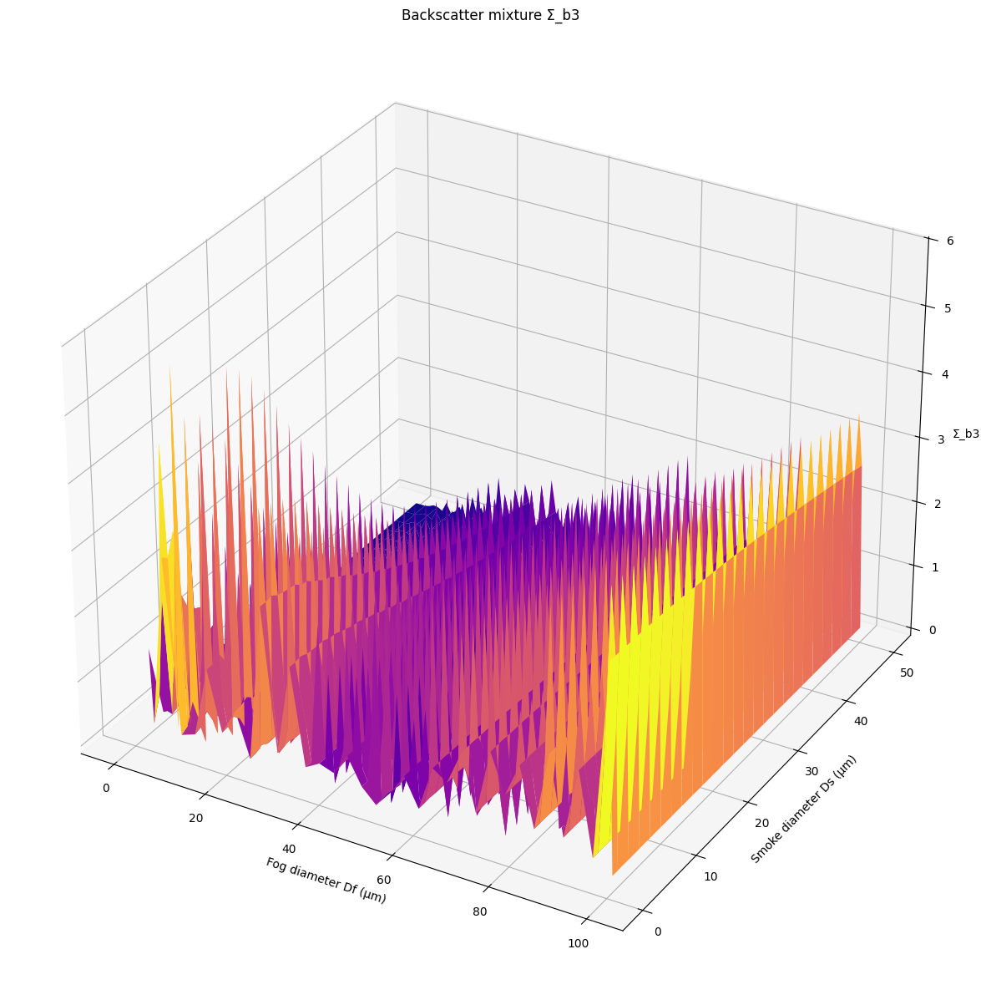

In [ ]:
fig = plt.figure(figsize=(36, 15))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf2 = ax1.plot_surface(Df_grid3, Ds_grid3, Sigma_b3, cmap='plasma', edgecolor='none')
ax1.set_title('Backscatter mixture Σ_b3')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.set_zlabel('Σ_b3')

ax1 = fig.add_subplot(1, 2, 1, projection='3d', cmap='viridis', edgecolor='none')
ax1.set_title('Extinction mixture Σ_ext3')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.set_zlabel('Σ_ext3')

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import miepython

# --- Physical parameters ---
wavelength = 905e-9          # LiDAR wavelength, meters
m_fog   = 1.33 + 0j          # refractive index fog droplets (water approx)
m_smoke = 1.50 + 0.01j       # example smoke index; adjust as needed

N_f = 1.0                    # relative number density, fog
N_s = 1.0                    # relative number density, smok

# --- Size grids (in micrometers for plotting) ---
Df_um = np.linspace(0.0, 100.0, 1001)     # fog diameters: 1–50 µm
Ds_um = np.linspace(0.0, 50.0, 501)     # smoke diameters: 0.1–10 µm

Df_grid3, Ds_grid3 = np.meshgrid(Df_um, Ds_um)   # shape (50, 50)

Sigma_b3 = np.zeros_like(Df_grid3, dtype=float) # z-axis: mixture backscatter
Sigma_ext3 = np.zeros_like(Ds_grid3, dtype=float) # z-axis: mixture extinction

# --- Helper to compute Qb for one species ---
def qb_for_sphere(m, D_m):
    x = np.pi * D_m / wavelength          # size parameter
    qext, qsca, qback, g = miepython.efficiencies_mx(m, x)
    return qback

def qext_for_sphere(m, D_m):
    x = np.pi * D_m / wavelength          # size parameter
    qext, qsca, qback, g = miepython.efficiencies_mx(m, x)
    return qext

# --- Main loop over (Df, Ds) grid ---
for i in range(Df_grid3.shape[0]):        # over smoke
    for j in range(Df_grid3.shape[1]):    # over fog

        # convert to meters
        Df_m3 = Df_grid3[i, j] * 1e-6      # fog diameter
        Ds_m3 = Ds_grid3[i, j] * 1e-6      # smoke diameter
        print(f"\n==i={i}, j = {j} Df_m={Df_m3:.3e} and Ds_m={Ds_m3:.3e} m===")

        # per-particle backscatter efficiencies
        Qb_f3 = qb_for_sphere(m_fog,   Df_m3)
        Qb_s3 = qb_for_sphere(m_smoke, Ds_m3)
        Qext_f3 = qext_for_sphere(m_fog,   Df_m3)
        Qext_s3 = qext_for_sphere(m_smoke, Ds_m3)

        # geometric cross-sections
        #sigma_f3 = np.pi * (Df_m3 / 2.0)**2
        #sigma_s3 = np.pi * (Ds_m3 / 2.0)**2


        # mixture backscatter per unit volume (relative)
        #Sigma_b3[i, j] = N_f * Qb_f3 * sigma_f3 + N_s * Qb_s3 * sigma_s3
        #Sigma_ext3[i, j] = N_f * Qext_f3 * sigma_f3 + N_s * Qext_s3 * sigma_s3
        Sigma_b3[i, j] = N_f * Qb_f3  + N_s * Qb_s3
        Sigma_ext3[i, j] = N_f * Qext_f3 + N_s * Qext_s3

# --- 3D surface plot ---

fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid3, Ds_grid3, Sigma_ext3,
                         cmap='viridis', edgecolor='none')
ax1.set_title('Extinction mixture Σ_ext3')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.set_zlabel('Σ_ext3')

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid3, Ds_grid3, Sigma_b3,
                         cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter mixture Σ_b3')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')
ax2.set_zlabel('Σ_b3')

plt.tight_layout()
plt.show()

Streaming output truncated to the last 5000 lines.

==i=498, j = 503 Df_m=5.040e-05 and Ds_m=4.990e-05 m===

==i=498, j = 504 Df_m=5.050e-05 and Ds_m=4.990e-05 m===

==i=498, j = 505 Df_m=5.060e-05 and Ds_m=4.990e-05 m===

==i=498, j = 506 Df_m=5.070e-05 and Ds_m=4.990e-05 m===

==i=498, j = 507 Df_m=5.080e-05 and Ds_m=4.990e-05 m===

==i=498, j = 508 Df_m=5.090e-05 and Ds_m=4.990e-05 m===

==i=498, j = 509 Df_m=5.100e-05 and Ds_m=4.990e-05 m===

==i=498, j = 510 Df_m=5.110e-05 and Ds_m=4.990e-05 m===

==i=498, j = 511 Df_m=5.120e-05 and Ds_m=4.990e-05 m===

==i=498, j = 512 Df_m=5.130e-05 and Ds_m=4.990e-05 m===

==i=498, j = 513 Df_m=5.140e-05 and Ds_m=4.990e-05 m===

==i=498, j = 514 Df_m=5.150e-05 and Ds_m=4.990e-05 m===

==i=498, j = 515 Df_m=5.160e-05 and Ds_m=4.990e-05 m===

==i=498, j = 516 Df_m=5.170e-05 and Ds_m=4.990e-05 m===

==i=498, j = 517 Df_m=5.180e-05 and Ds_m=4.990e-05 m===

==i=498, j = 518 Df_m=5.190e-05 and Ds_m=4.990e-05 m===

==i=498, j = 519 Df_m=5.200e-05 and 

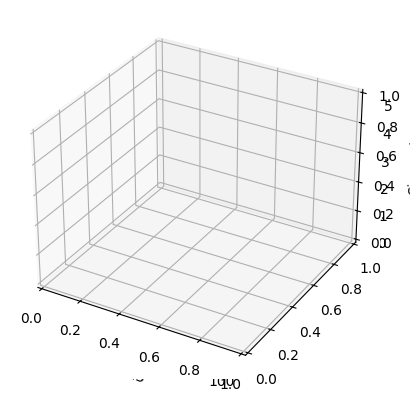

In [ ]:
#x = np.linspace(-5, 5, 50)
#y = np.linspace(-5, 5, 50)
#X, Y = np.meshgrid(x, y)###
#Z = np.sin(np.sqrt(X**2 + Y**2))

Df_um = np.linspace(0.1, 100.1, 1001)     # fog diameters: 1–50 µm
Ds_um = np.linspace(0.1, 50.1, 501)     # smoke diameters: 0.1–10 µm
Df_grid3, Ds_grid3 = np.meshgrid(Df_um, Ds_um)   # shape (50, 50)
Sigma_b3[]
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax2= fig.add_subplot(111, projection='3d')

ax.plot_surface(Df_grid3, Ds_grid3, Sigma_ext3, cmap='viridis', edgecolor='none')
ax.set_xlabel('Df_grid3')
ax.set_ylabel('Ds_grid3')
ax.set_zlabel('Sigma_ext3')
ax.plot_surface(Df_grid3, Ds_grid3, Sigma_b3, cmap='viridis', edgecolor='none')
ax.set_xlabel('Df_grid3')
ax.set_ylabel('Ds_grid3')
ax.set_zlabel('Sigma_b3')
plt.show()


In [ ]:

# 4) Plot
plt.figure()
plt.plot(D_um, Qext, label='Q_ext')
plt.plot(D_um, Qb,   label='Q_b')
plt.xlabel('Droplet diameter D (µm)')
plt.ylabel('Efficiency')
plt.legend()
plt.grid(True)
plt.show()

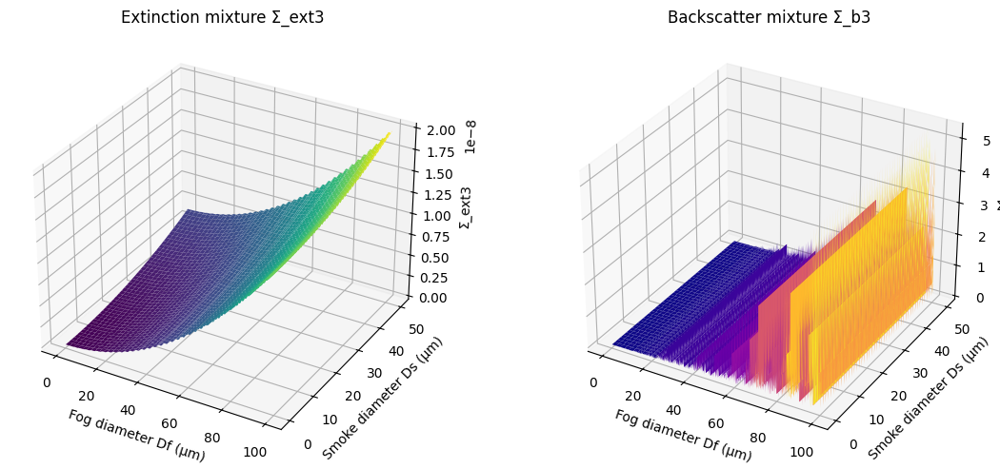

In [ ]:
fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid3, Ds_grid3, Sigma_ext3,
                         cmap='viridis', edgecolor='none')
ax1.set_title('Extinction mixture Σ_ext3')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.set_zlabel('Σ_ext3')

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(Df_grid3, Ds_grid3, Sigma_b3,
                         cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter mixture Σ_b3')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')
ax2.set_zlabel('Σ_b3')

plt.tight_layout()
plt.show()

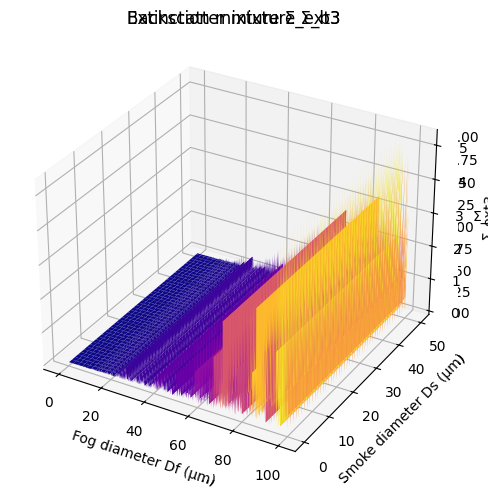

In [ ]:
fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(Df_grid3, Ds_grid3, Sigma_ext3,
                         cmap='viridis', edgecolor='none')
ax1.set_title('Extinction mixture Σ_ext3')
ax1.set_xlabel('Fog diameter Df (µm)')
ax1.set_ylabel('Smoke diameter Ds (µm)')
ax1.set_zlabel('Σ_ext3')

ax2 = fig.add_subplot(1, 2, 1, projection='3d')
surf2 = ax2.plot_surface(Df_grid3, Ds_grid3, Sigma_b3,
                         cmap='plasma', edgecolor='none')
ax2.set_title('Backscatter mixture Σ_b3')
ax2.set_xlabel('Fog diameter Df (µm)')
ax2.set_ylabel('Smoke diameter Ds (µm)')
ax2.set_zlabel('Σ_b3')

plt.tight_layout()
plt.show()

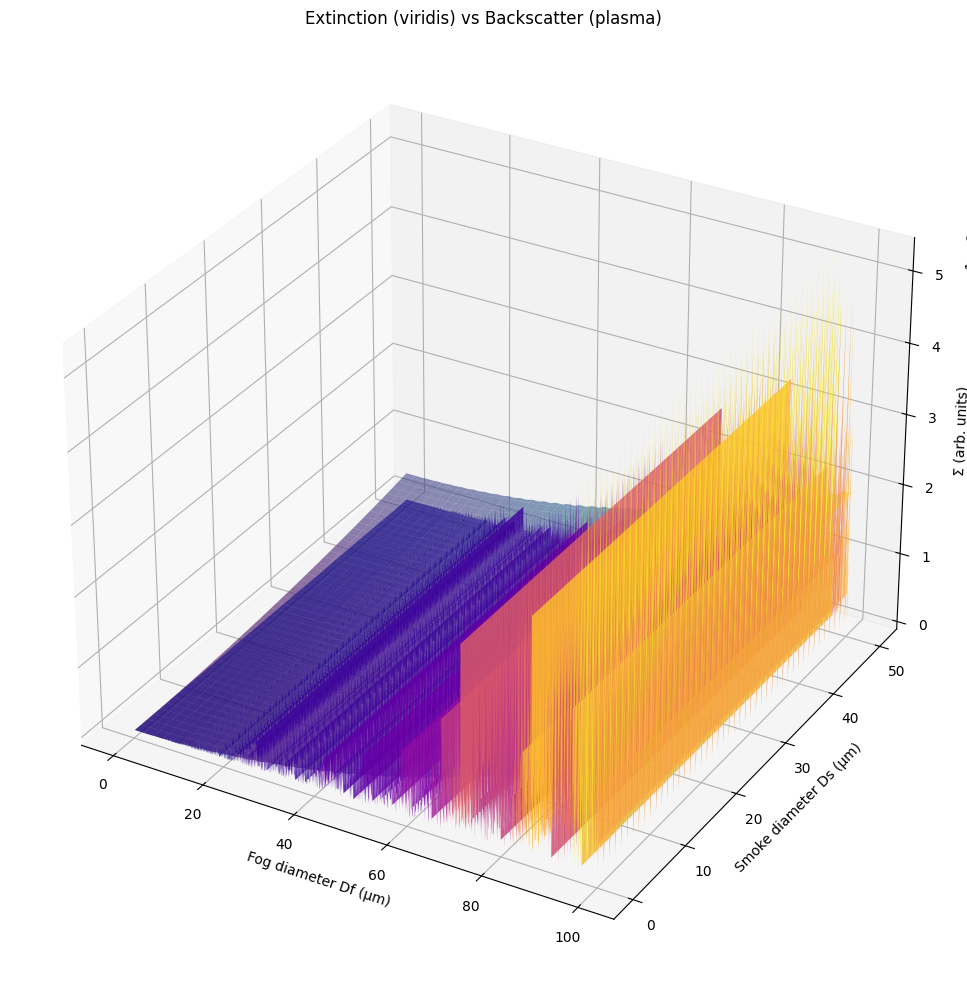

In [ ]:
fig = plt.figure(figsize=(24, 10))
ax = fig.add_subplot(111, projection='3d')

# Extinction surface
ax.plot_surface(Df_grid3, Ds_grid3, Sigma_ext3,
                cmap='viridis', alpha=0.6, edgecolor='none',
                label='Σ_ext3')  # label used only for legend proxy

# Backscatter surface
ax.plot_surface(Df_grid3, Ds_grid3, Sigma_b3,
                cmap='plasma', alpha=0.6, edgecolor='none',
                label='Σ_b3')

ax.set_xlabel('Fog diameter Df (µm)')
ax.set_ylabel('Smoke diameter Ds (µm)')
ax.set_zlabel('Σ (arb. units)')
ax.set_title('Extinction (viridis) vs Backscatter (plasma)')

plt.tight_layout()
plt.show()

In [ ]:
wavelength = 905e-9          # LiDAR wavelength, meters
m_fog   = 1.33 + 0j          # refractive index fog droplets (water approx)
m_smoke = 1.50 + 0.01j       # example smoke index; adjust as needed

N_f = 1.0                    # relative number density, fog
N_s = 1.0                    # relative number density, smoke

Df_um = np.linspace(0.1, 100.1, 1001)     # fog diameters: 1–50 µm
Ds_um = np.linspace(0.1, 50.1, 501)     # smoke diameters: 0.1–10 µm
Df_grid3, Ds_grid3 = np.meshgrid(Df_um, Ds_um)   # shape (50, 50)

def qb_for_sphere(m, D_m):
    x = np.pi * D_m / wavelength
    qext, qsca, qback, g = miepython.efficiencies_mx(m, x)
    return qback

def qext_for_sphere(m, D_m):
    x = np.pi * D_m / wavelength
    qext, qsca, qback, g = miepython.efficiencies_mx(m, x)
    return qext

for i in range(Df_grid3.shape[0]):        # over smoke
    for j in range(Df_grid3.shape[1]):    # over fog

        # convert to meters
        Df_m3 = Df_grid3[i, j] * 1e-6      # fog diameter
        Ds_m3 = Ds_grid3[i, j] * 1e-6      # smoke diameter

        # per-particle backscatter efficiencies
        Qb_f3 = qb_for_sphere(m_fog,   Df_m3)
        Qb_s3 = qb_for_sphere(m_smoke, Ds_m3)
        Qext_f3 = qext_for_sphere(m_fog,   Df_m3)
        Qext_s3 = qext_for_sphere(m_smoke, Ds_m3)

        # geometric cross-sections
        sigma_f3 = np.pi * (Df_m3 / 2.0)**2
        sigma_s3 = np.pi * (Ds_m3 / 2.0)**2

        # mixture backscatter per unit volume (relative)
        Sigma_b3[i, j] = N_f * Qb_f3 * sigma_f3 + N_s * Qb_s3 * sigma_s3
        Sigma_ext3[i, j] = N_f * Qext_f3 * sigma_f3 + N_s * Qext_s3 * sigma_s3

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax2= fig.add_subplot(111, projection='3d')

ax.plot_surface(Df_grid3, Ds_grid3, Sigma_ext3, cmap='viridis', edgecolor='none')
ax.set_xlabel('Df_grid3')
ax.set_ylabel('Ds_grid3')
ax.set_zlabel('Sigma_ext3')
ax.plot_surface(Df_grid3, Ds_grid3, Sigma_b3, cmap='viridis', edgecolor='none')
ax.set_xlabel('Df_grid3')
ax.set_ylabel('Ds_grid3')
ax.set_zlabel('Sigma_b3')
plt.show()

In [ ]:
Df_um = np.linspace(0.1, 100.1, 51)     # fog diameters: 1–50 µm
Ds_um = np.linspace(50.1, 0.1,51)     # smoke diameters: 0.1–10 µm
Df_umx= np.linspace(0.1, 100.1, 101)     # fog diameters: 1–50 µm
Ds_umx= np.linspace(50.1, 0.1, 101)     # smoke diameters: 0.1–10 µm